In [22]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('charm_all.csv')

In [23]:
import vector as vec

In [24]:
import numpy as np
from scipy import optimize
import uproot
import awkward as ak

In [25]:
ak1_file = uproot.open('nanoAOD_reclustered_AK1.root:Events')

ak1_file.keys()

['EventAuxiliary',
 'EventProductProvenance',
 'EventSelections',
 'BranchListIndexes',
 'patJets_slimmedJets__PAT.',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.present',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fX',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fY',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.vertex_.fCoordinates.fZ',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_slimmedJets__PAT./patJ

need ratio of energy of ak1 to ak4, ~0.8-0.9, energy can be found using vector library as 4 vector

check divergence of eta to match ak1s with ak4s

In [26]:
ak1_data = ak1_file.arrays(['int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj',
                            'int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj',
                            'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.vertex_.fCoordinates.fX',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.vertex_.fCoordinates.fY',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.vertex_.fCoordinates.fZ',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM',
  'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.jetCharge_'
 ])
ak1_pd = ak.to_dataframe(ak1_data)
ak1_pd.rename(columns = {'int_eventIdProducer_run_RECLUSTER./int_eventIdProducer_run_RECLUSTER.obj':'run',
                            'int_eventIdProducer_event_RECLUSTER./int_eventIdProducer_event_RECLUSTER.obj':'event',
                            'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.vertex_.fCoordinates.fX':'ak1_vertx',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.vertex_.fCoordinates.fY':'ak1_verty',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.vertex_.fCoordinates.fZ':'ak1_vertz',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPt':'ak1_pt',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fEta':'ak1_eta',
 'patJets_slimmedJets__PAT./patJets_slimmedJets__PAT.obj/patJets_slimmedJets__PAT.obj.m_state.p4Polar_.fCoordinates.fPhi':'ak1_phi',
 'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.m_state.p4Polar_.fCoordinates.fM':'ak1_mass',
  'patJets_reclusterAK1__RECLUSTER./patJets_reclusterAK1__RECLUSTER.obj/patJets_reclusterAK1__RECLUSTER.obj.jetCharge_':'ak1_charge'},inplace = True)
ak1_pd

run      event  ak1_vertx  ak1_verty  ak1_vertz     ak1_pt  \
entry subentry                                                                  
0     0         281976  521846398        0.0        0.0        0.0  21.287710   
      1         281976  521846398        0.0        0.0        0.0  16.926594   
      2         281976  521846398        0.0        0.0        0.0  13.577738   
      3         281976  521846398        0.0        0.0        0.0  13.526744   
      4         281976  521846398        0.0        0.0        0.0  12.149314   
...                ...        ...        ...        ...        ...        ...   
999   8         281976  521681148        0.0        0.0        0.0  11.526770   
      9         281976  521681148        0.0        0.0        0.0  11.059496   
      10        281976  521681148        0.0        0.0        0.0  10.686631   
      11        281976  521681148        0.0        0.0        0.0  10.598081   
      12        281976  521681148        0.0        0.0        0.0  10.595553   

                 ak1_eta   ak1_phi      ak1_mass  ak1_charge  
entry subentry                                                
0     0        -3.437167  3.054484 -1.907349e-06         0.0  
      1        -3.512425  0.586143  7.977068e-02         0.0  
      2        -0.742079 -0.432655  1.907349e-06         0.0  
      3        -3.577233 -1.321024  6.743496e-07         0.0  
      4        -2.883712  0.255492  1.395264e-01         0.0  
...                  ...       ...           ...         ...  
999   8         2.489133  1.507148 -9.536743e-07         0.0  
      9         3.715191 -3.098444 -6.029909e-08         0.0  
      10        3.387047 -0.168008  6.743496e-07         0.0  
      11       -0.426147  2.700764  1.952130e-01         0.0  
      12        1.306782 -1.409415  0.000000e+00         0.0  

[8868 rows x 10 columns]

In [27]:
ak1_pd = ak1_pd.loc[ak1_pd.ak1_mass > 1.8]
ak1_pd

,,run,event,ak1_vertx,ak1_verty,ak1_vertz,ak1_pt,ak1_eta,ak1_phi,ak1_mass,ak1_charge
entry,subentry,,,,,,,,,,
52,0,281976,523225600,0.0,0.0,0.0,67.145432,-0.634662,0.962378,2.635731,0.0
66,0,281976,522947047,0.0,0.0,0.0,84.892960,-1.960250,2.733319,2.363806,0.0
80,0,281976,522660488,0.0,0.0,0.0,190.178711,0.605624,-3.006094,5.026573,0.0
89,0,281976,522113024,0.0,0.0,0.0,133.020187,0.076666,-2.163131,3.921953,0.0
121,0,281976,522715589,0.0,0.0,0.0,98.527939,1.265640,2.136599,2.160758,0.0
146,0,281976,521797724,0.0,0.0,0.0,74.681786,0.211472,-0.875599,2.327439,0.0
221,0,281976,522957335,0.0,0.0,0.0,154.743607,0.937452,2.065648,3.383346,0.0
235,0,281976,522638551,0.0,0.0,0.0,35.849930,-1.141583,-0.578637,1.967592,0.0
291,0,281976,522551439,0.0,0.0,0.0,159.479462,0.294907,-1.937428,2.302343,0.0


In [28]:
ak1_vec = vec.array({'pt':ak1_pd.ak1_pt,'eta':ak1_pd.ak1_eta,'phi':ak1_pd.ak1_phi,'mass':ak1_pd.ak1_mass})
ak1_energy = ak1_vec.e

(array([0., 5., 6., 8., 6., 4., 0., 1., 0., 0.]),
 array([  0.,  40.,  80., 120., 160., 200., 240., 280., 320., 360., 400.]),
 <BarContainer object of 10 artists>)

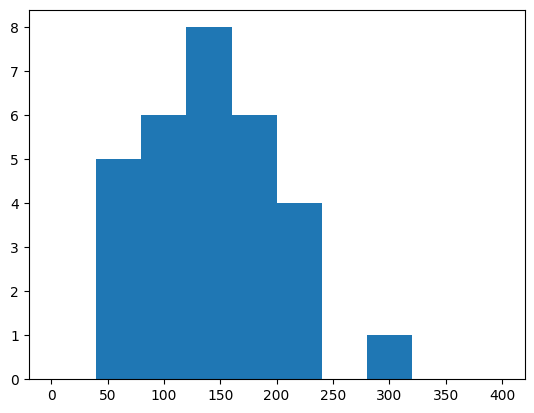

In [29]:
plt.hist(ak1_energy, range = (0,400))

(array([10.,  4.,  5.,  4.,  0.,  3.,  0.,  1.,  0.,  2.,  0.,  0.,  0.,
         0.,  1.,  0.,  0.,  0.,  0.,  1.]),
 array([1.81638515, 2.03975125, 2.26311735, 2.48648345, 2.70984955,
        2.93321565, 3.15658175, 3.37994785, 3.60331395, 3.82668005,
        4.05004615, 4.27341225, 4.49677835, 4.72014444, 4.94351054,
        5.16687664, 5.39024274, 5.61360884, 5.83697494, 6.06034104,
        6.28370714]),
 <BarContainer object of 20 artists>)

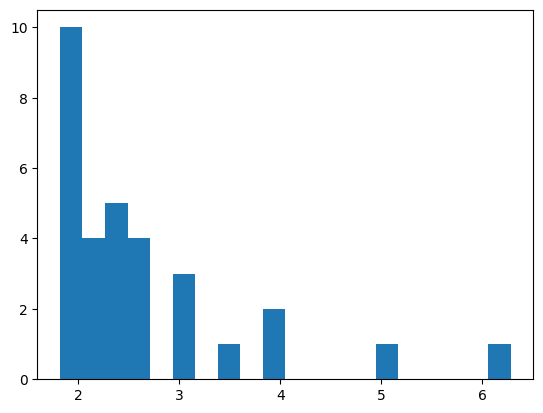

In [30]:
plt.hist(ak1_pd.ak1_mass, bins = 20)

ak1 graphs (for like 1000 events) with mass greater than 1.8

Text(0.5, 1.0, 'Jet phi')

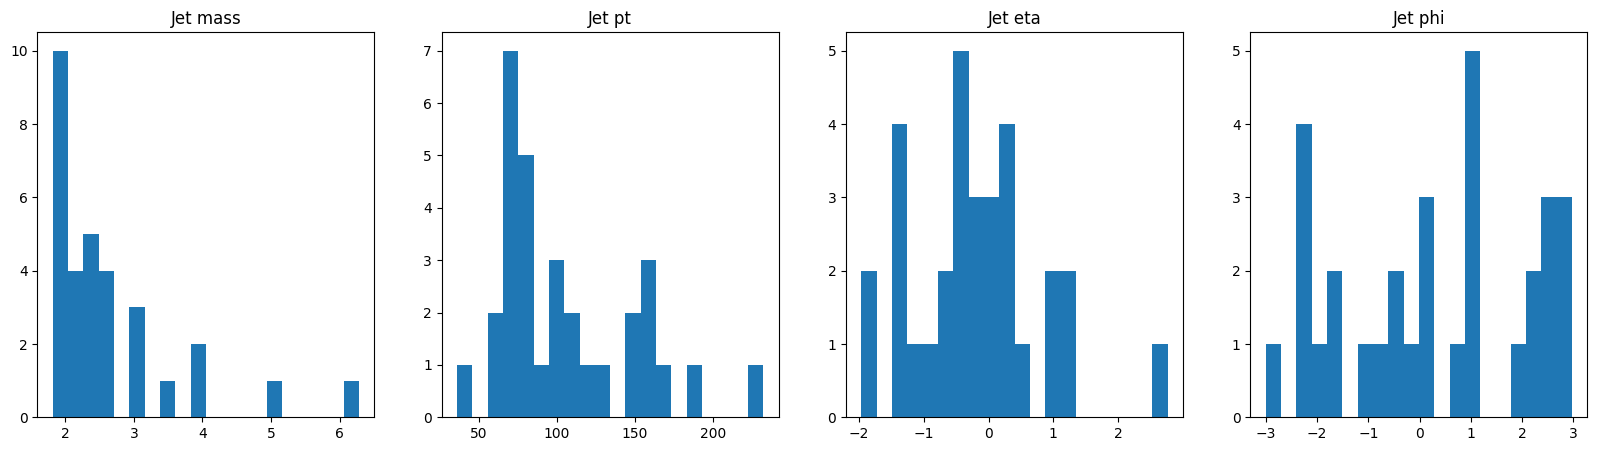

In [31]:
binsize = 20
fig1, axs = plt.subplots(1,4,figsize =(20,5))
axs[0].hist(ak1_pd.ak1_mass, bins = binsize)
axs[0].set_title('Jet mass')

axs[1].hist(ak1_pd.ak1_pt, bins = binsize)
axs[1].set_title('Jet pt')

axs[2].hist(ak1_pd.ak1_eta, bins = binsize)
axs[2].set_title('Jet eta')
        
axs[3].hist(ak1_pd.ak1_phi, bins = binsize)
axs[3].set_title('Jet phi')

In [32]:
with_ak1 = df.merge(ak1_pd, on=['run', 'event'])

In [33]:
with_ak1

,Unnamed: 0,run,event,Mu_mass,Mupos_pt,Mupos_eta,Mupos_phi,Mupos_charge,Muneg_pt,Muneg_eta,...,wc_eta,wc_phi,ak1_vertx,ak1_verty,ak1_vertz,ak1_pt,ak1_eta,ak1_phi,ak1_mass,ak1_charge
0,9821644,281976,522947047,0.105658,4.609568,-1.722168,2.641602,1,23.092869,-2.013184,...,-1.242723,2.564535,0.0,0.0,0.0,84.892960,-1.960250,2.733319,2.363806,0.0
1,9821664,281976,521797724,0.105658,8.606223,0.280884,2.252441,1,37.264410,0.117676,...,0.670872,2.116226,0.0,0.0,0.0,74.681786,0.211472,-0.875599,2.327439,0.0
2,9821686,281976,522551439,0.105658,5.578813,0.328857,-2.106934,1,13.644430,0.311829,...,2.626872,-2.806488,0.0,0.0,0.0,159.479462,0.294907,-1.937428,2.302343,0.0
3,9821688,281976,522403891,0.105658,4.935805,-0.288208,0.157776,1,24.371424,-0.319458,...,1.703499,-1.037600,0.0,0.0,0.0,64.741287,-0.321219,-0.099284,2.009537,0.0
4,9821689,281976,522403891,0.105658,4.935805,-0.288208,0.157776,1,24.371424,-0.319458,...,-1.340659,0.867399,0.0,0.0,0.0,64.741287,-0.321219,-0.099284,2.009537,0.0
5,9821693,281976,522783467,0.105658,5.711110,1.990967,1.087402,1,19.921232,2.295898,...,3.228976,1.597300,0.0,0.0,0.0,57.117107,-0.205505,-1.682616,2.078324,0.0
6,9821720,281976,522085154,0.105658,14.151003,1.150391,1.684326,1,11.187377,1.302490,...,-2.402396,2.827258,0.0,0.0,0.0,172.315475,0.217581,0.091964,3.922527,0.0
7,9821720,281976,522085154,0.105658,14.151003,1.150391,1.684326,1,11.187377,1.302490,...,-2.402396,2.827258,0.0,0.0,0.0,112.318581,-0.405815,-2.139511,3.058997,0.0
8,9821733,281976,522553759,0.105658,6.639838,-1.714111,-1.483643,1,10.869678,-1.602295,...,2.265820,-2.467242,0.0,0.0,0.0,69.382935,-1.422751,0.940936,2.644528,0.0
9,9821778,281976,522577049,0.105658,6.311420,-0.188019,0.141968,1,12.302979,0.158264,...,-1.845944,-0.435958,0.0,0.0,0.0,157.214615,0.032368,0.040422,3.142339,0.0


In [34]:
def jpsi_hist(frame):
    fig, axs = plt.subplots(1,4,figsize = (20,5))
    axs[0].hist(frame.jpsi_mass, bins = 50, range = (2.9, 4.9))
    axs[0].set_title('Jpsi mass')
    axs[1].hist(frame.jpsi_pt, bins= 50, range = (0,100))
    axs[1].set_title('Jpsi pt')
    axs[2].hist(frame.jpsi_eta, bins = 50)
    axs[2].set_title('Jpsi eta')
    axs[3].hist(frame.jpsi_phi, bins = 50)
    axs[3].set_title('Jpsi phi')

In [35]:
def mu_hist(frame):
    fig, axs = plt.subplots(1,4, figsize = (20,5))
    axs[0].hist(frame.Mupos_pt, bins = 100, label = 'Positive', histtype = 'step', range = (0, 50))
    axs[0].hist(frame.Muneg_pt, bins = 100, label = 'Negative', histtype = 'step', range = (0, 50))
    axs[0].legend()
    axs[0].set_title('Muon pt')
    
    axs[1].hist(frame.Mupos_eta, bins = 100, label = 'Positive', histtype = 'step')
    axs[1].hist(frame.Muneg_eta, bins = 100, label = 'Negative', histtype = 'step')
    axs[1].legend()
    axs[1].set_title('Muon eta')

    axs[2].hist(frame.Mupos_phi, bins = 100, label = 'Positive', histtype = 'step')
    axs[2].hist(frame.Muneg_phi, bins = 100, label = 'Negative', histtype = 'step')
    axs[2].legend()
    axs[2].set_title('Muon phi')

    axs[3].hist(frame.nMuon)
    axs[3].set_title('Number of Muons')

In [36]:
def jet_hist(frame):
    binsize = 50
    btag = ["Jet_bRegCorr", "Jet_bRegRes", "Jet_btagCSVV2", "Jet_btagDeepB", "Jet_btagDeepCvB", "Jet_btagDeepCvL", 'Jet_btagDeepFlavB', 'Jet_btagDeepFlavCvB', 'Jet_btagDeepFlavCvL', 'Jet_btagDeepFlavQG']
    
    fig1, axs = plt.subplots(1,4,figsize =(20,5))
    axs[0].hist(frame.Jet_mass, bins = binsize)
    axs[0].set_title('Jet mass')

    axs[1].hist(frame.Jet_pt, bins = binsize, range = (0,50))
    axs[1].set_title('Jet pt')

    axs[2].hist(frame.Jet_eta, bins = binsize)
    axs[2].set_title('Jet eta')
    
    axs[3].hist(frame.Jet_phi, bins = binsize)
    axs[3].set_title('Jet phi')

    fig2, axs = plt.subplots(2, 5, figsize = (25, 10))

    for val in btag:
        idx = btag.index(val)
        if idx<=4:
            axs[0,idx].hist(frame[val], bins = binsize)
            axs[0,idx].set_title(val)
        else:
            axs[1, idx-5].hist(frame[val], bins = binsize)
            axs[1, idx-5].set_title(val)
    

In [37]:
def wc_hist(frame):
    fig, axs = plt.subplots(1,5, figsize = (25,5))

    axs[0].hist(frame.wc_mass, bins = 100, range = (0,200))
    axs[0].set_title('W candidate mass')

    axs[1].hist(frame.wc_pt, bins = 50, range = (0,100))
    axs[1].set_title('W candidate pt')

    axs[2].hist(frame.wc_eta, bins = 50)
    axs[2].set_title('W candidate eta')
    
    axs[3].hist(frame.wc_phi, bins = 50)
    axs[3].set_title('W candidate phi')

    axs[4].hist(frame.wc_mass, bins = 40, range = (60,100))
    axs[4].set_title('Zoomed in W candidate mass')


In [38]:
def full_hist(frame, cut):
    print(cut) # string that describes selection criteria
    #run_hist(frame) 
    jpsi_hist(frame)
    #mu_hist(frame)
    jet_hist(frame)
    wc_hist(frame)

In [39]:
def wc_hist_comp(frame1,desc1,frame2,desc2):
    plt.hist(frame1.wc_mass, label=desc1, bins = 100, range = (60,100), histtype = 'step', color = 'red')
    plt.hist(frame2.wc_mass, label=desc2, bins = 100, range = (60,100), histtype = 'step', color = 'purple')
    plt.legend()
    plt.title('W candidate mass comparison between 2 cuts')

In [40]:
def jpsi_out(frame, low_val, high_val):
    new_frame = frame.loc[(frame.jpsi_mass<low_val)|(frame.jpsi_mass>high_val)]
    return new_frame, f"jpsi mass outside range: {low_val} to {high_val}"

In [41]:
def jpsi_in(frame, low_val, high_val):
    new_frame = frame.loc[(frame.jpsi_mass>low_val)&(frame.jpsi_mass<high_val)]
    return new_frame, f"jpsi mass within range {low_val} to {high_val}"

In [42]:
def jet_req(frame, low_val, high_val):
    new_frame = frame.loc[(frame.Jet_mass>low_val)&(frame.Jet_mass<high_val)]
    return new_frame, f"jet mass in range: {low_val} to {high_val}"

In [43]:
def btag_req(frame, tagname, low_val, high_val):
    # format of tagname should be just the part of the name after Jet_btag
    btag = f"Jet_btag{tagname}"
    new_frame = frame.loc[(frame[btag]>low_val)&(frame[btag]<high_val)]
    return new_frame, f"{btag} in range: {low_val} to {high_val}"

In [44]:
def jpsi_vs_w(frame, desc):
    plt.hist2d(frame.jpsi_mass, frame.wc_mass, bins = 200)
    plt.ylim(top = 120)
    plt.title(f"Jpsi vs W candidate masses: {desc}")
    plt.xlabel("Jpsi mass")
    plt.ylabel("W candidate mass")


In [45]:
def integrate_hist(rng_lo, rng_hi, bin_num, frame):
    nums, widths, graph = plt.hist(frame.wc_mass, range = (rng_lo,rng_hi), bins = bin_num)
    binsize = (rng_hi - rng_lo)/bin_num
    integral = sum(nums)*binsize
    return integral, nums, widths

5308461.600000001


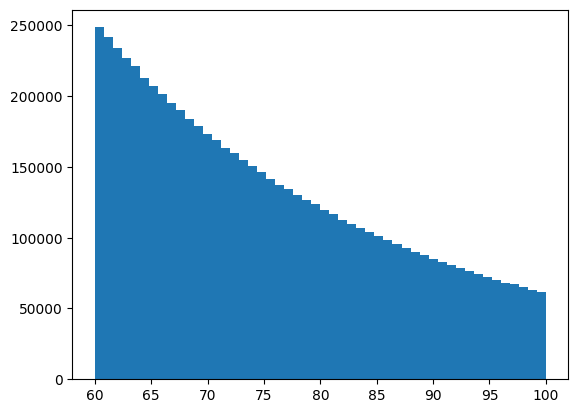

In [46]:
rng_hi = 100
rng_lo = 60
bin_num = 50
nums, widths, graph = plt.hist(df.wc_mass, range = (rng_lo,rng_hi), bins = bin_num)
binsize = (rng_hi - rng_lo)/bin_num
integral = sum(nums)*binsize
print(integral)

In [47]:
def hist_subtract_integral(frame1,frame2):
    bkgd_int, bkgd_vals, bkgd_wid = integrate_hist(60,100,50,frame1)
    new_int, new_vals, new_wid = integrate_hist(60,100,50,frame2)

    ratio = new_int/bkgd_int

    minus_bkgd = new_vals - bkgd_vals*ratio

    fig, ax = plt.subplots()
    ax.stairs(minus_bkgd, new_wid)
    ax.hlines(0, 60, 100)
    fig.show()

In [48]:
def scale_p_by(p, val):
    p0 = p[0]*val
    p4 = p[3]*val
    return [p0, p[1], p[2], p4]


In [49]:
def expo_fit(frame):
    counts, edges, graph = plt.hist(frame.wc_mass, bins = 100, range =(70,90), label = 'Histogram of W Candidate masses (GeV)', histtype = 'step')
    x = edges[:-1]
    y = counts
    p0 = [250000., -0.5, -60., 0.]
    expfit = lambda p, x: p[0]*np.exp(p[1]*(x+p[2]))+p[3]
    experr = lambda p, x, y: expfit(p,x)-y
    p2, success = optimize.leastsq(experr, p0[:], args = (x, y))
    plt.plot(x, expfit(p2, x), label = 'Line of best fit')
    plt.legend()
    print(f"Line of best fit eq: y = ({p2[0]})exp[{p2[1]}(x+{p2[2]})]+{p2[3]}")
    return [p2[0],p2[1],p2[2],p2[3]]

no cut


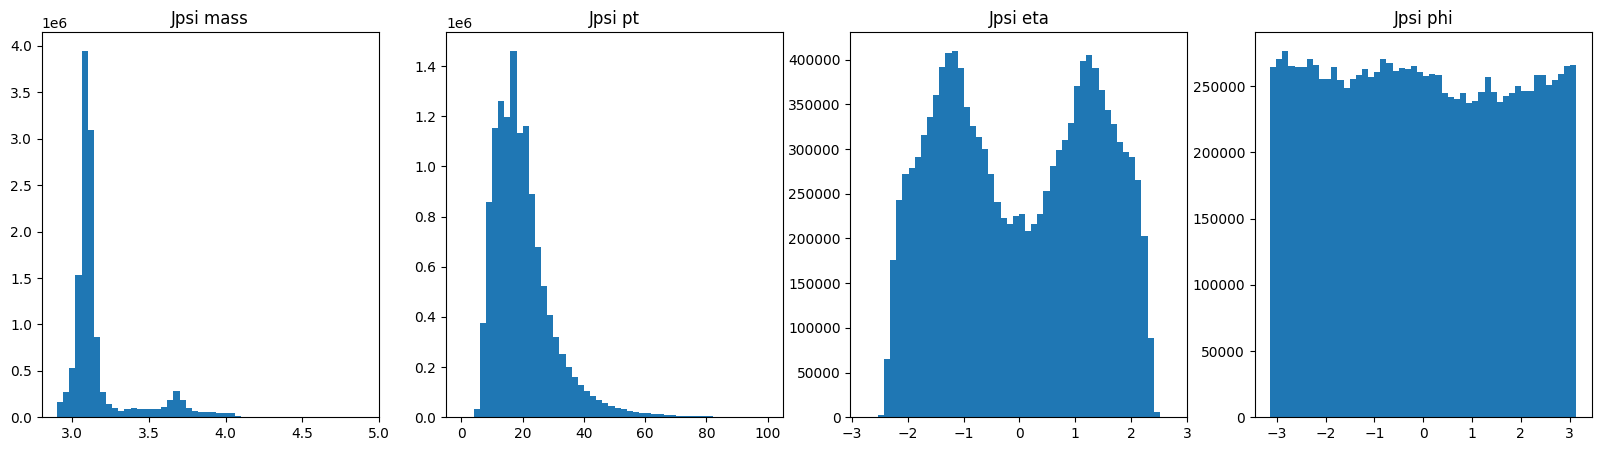

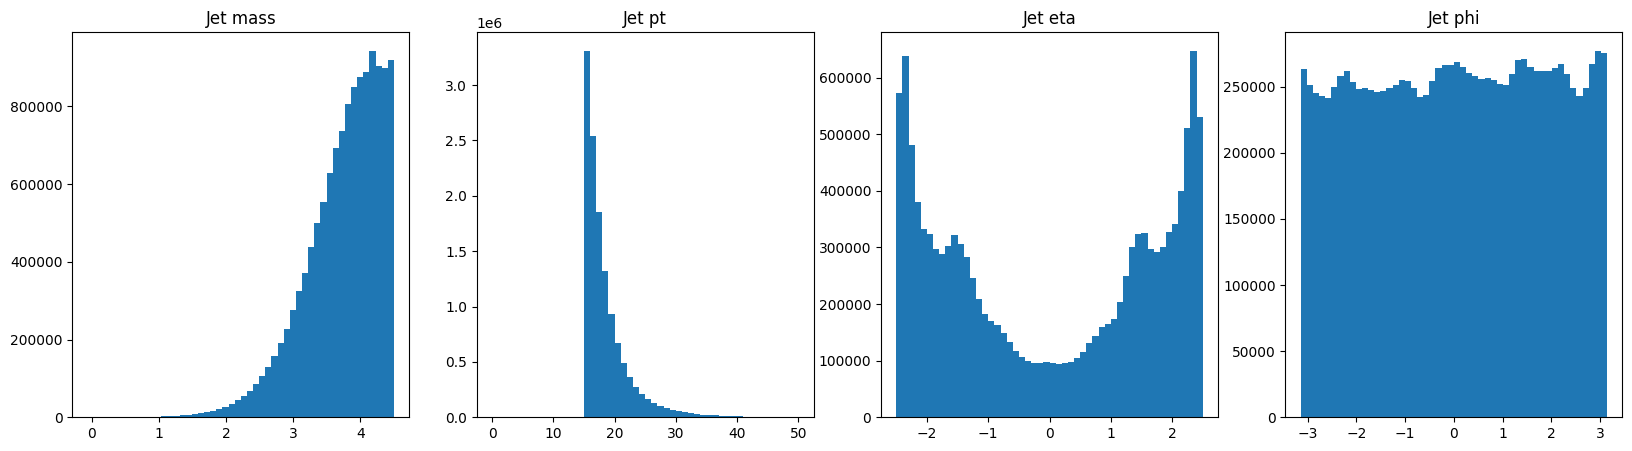

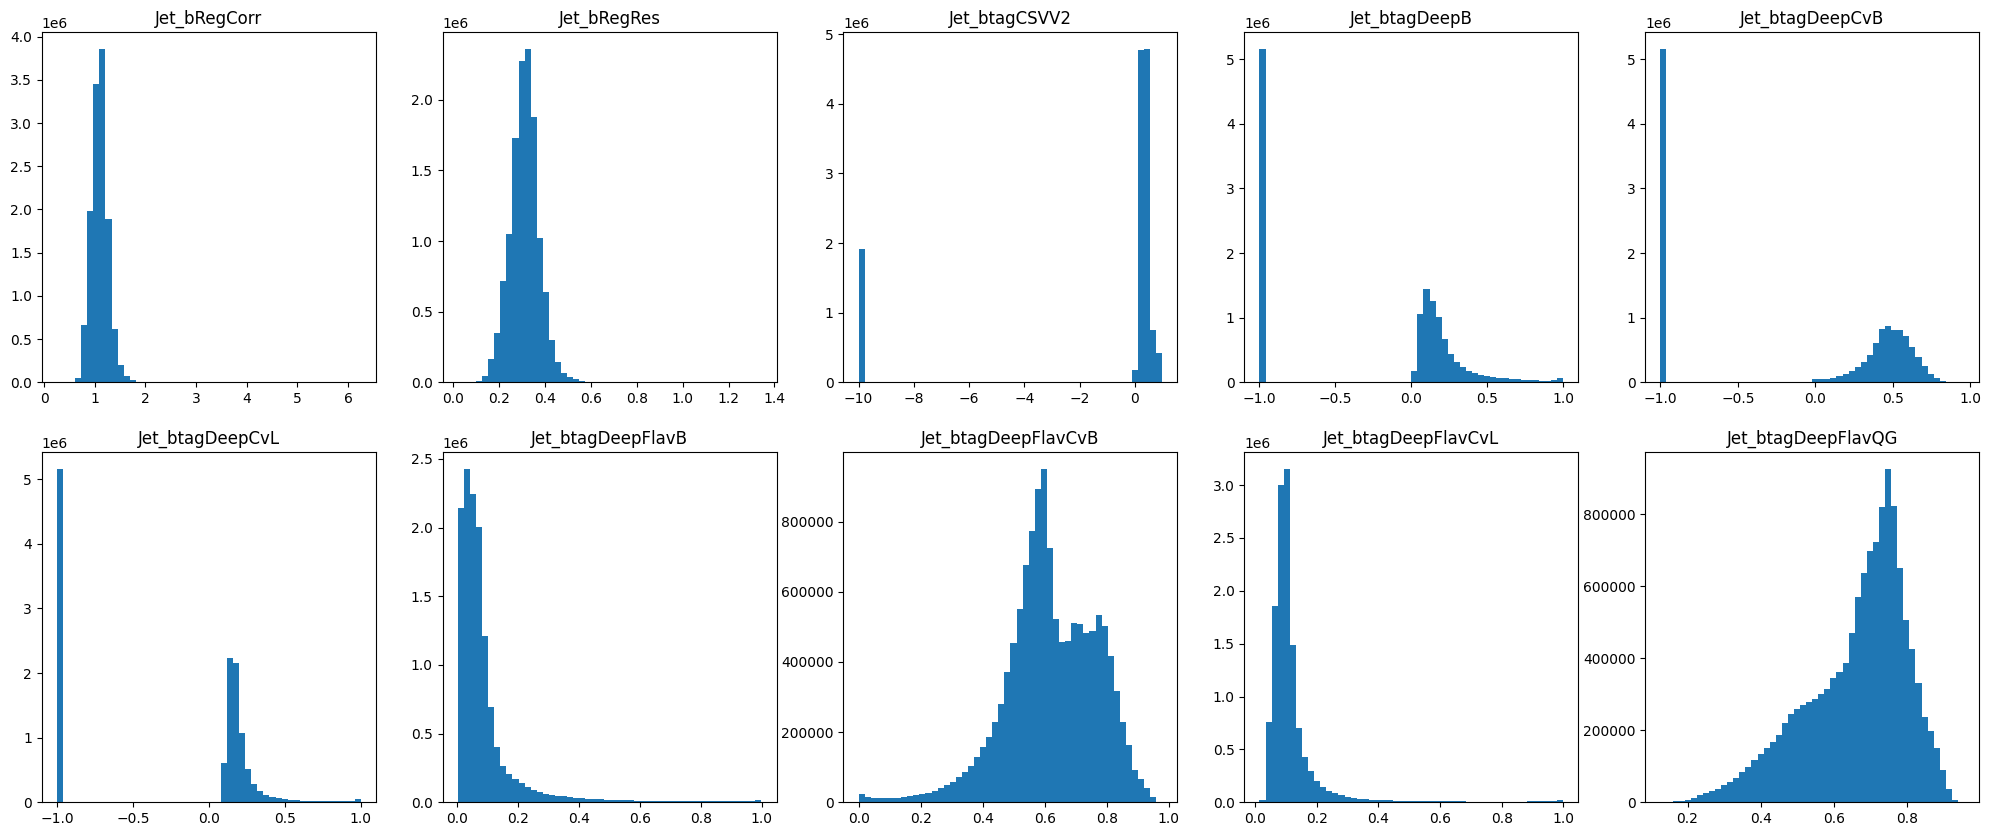

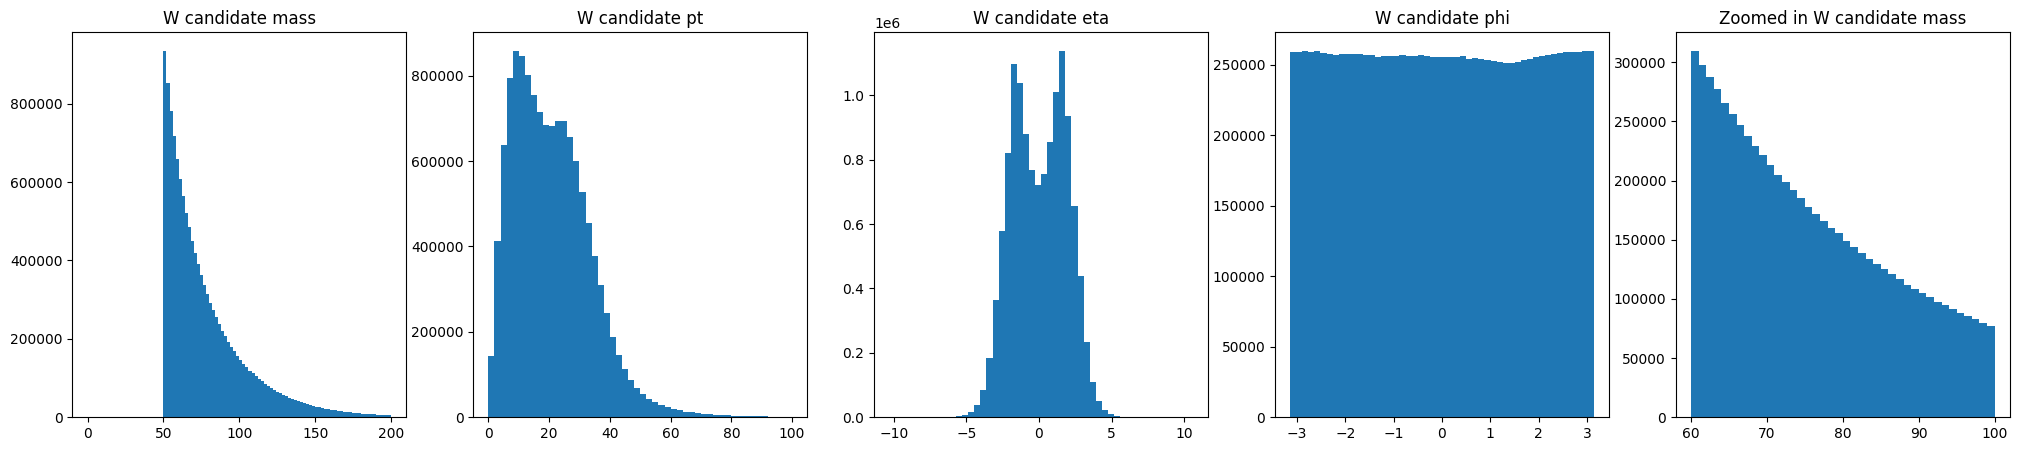

In [50]:
full_hist(df, 'no cut')

drop jet mass
btag cuts to try:
deepjet cvsb > 0.4 ish
deepjet cvsl > 0.5 ish


Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


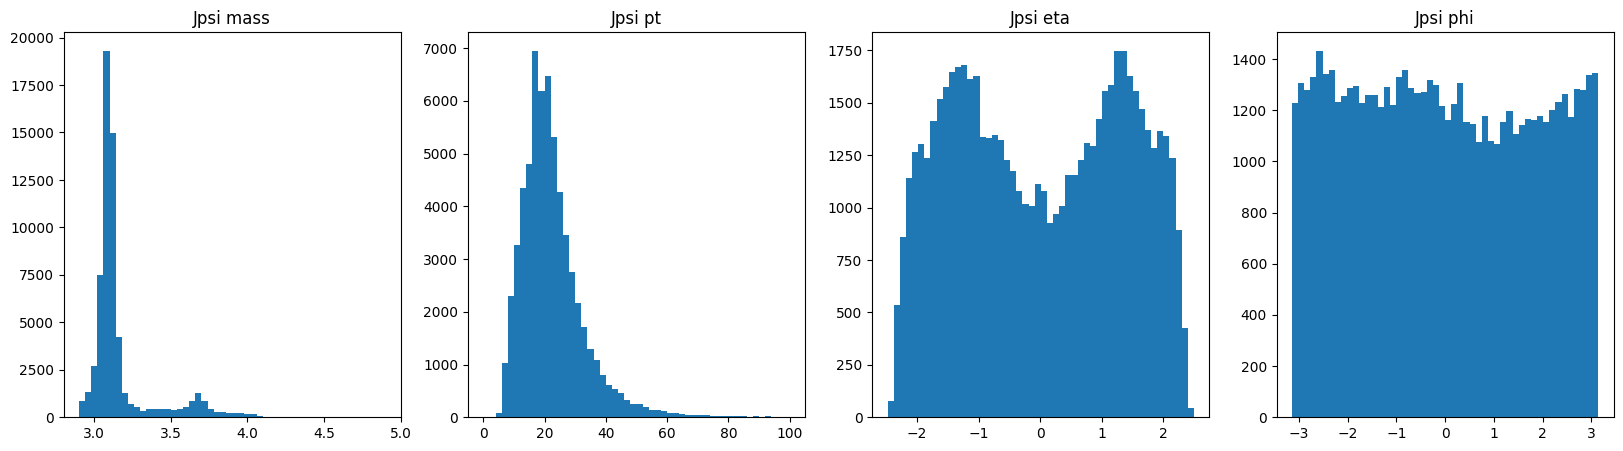

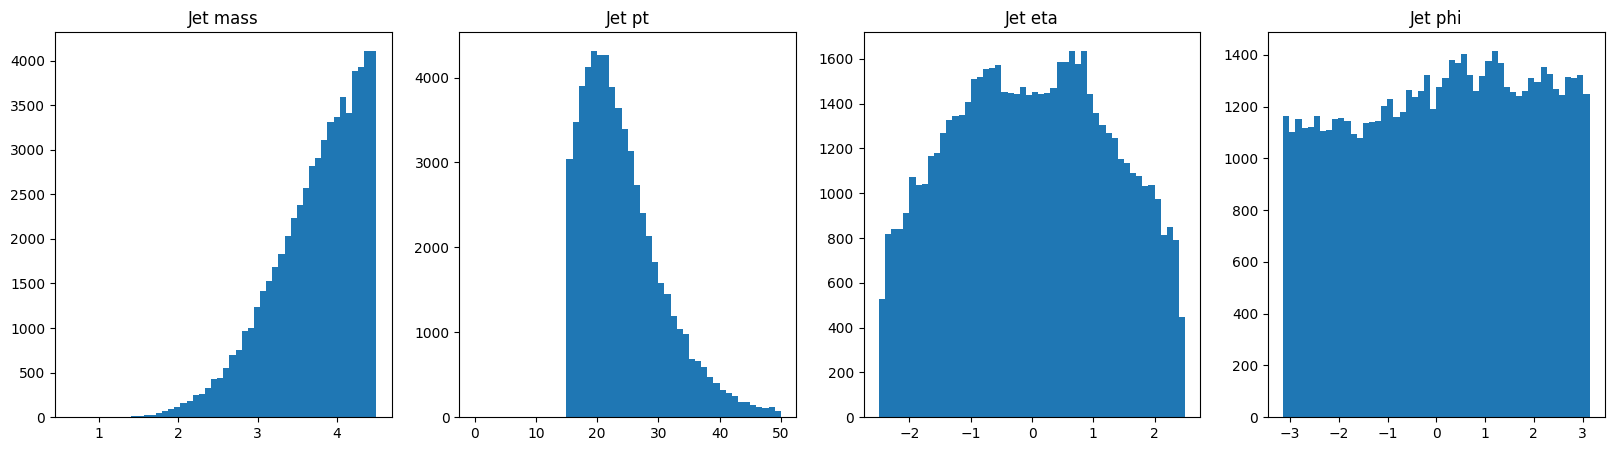

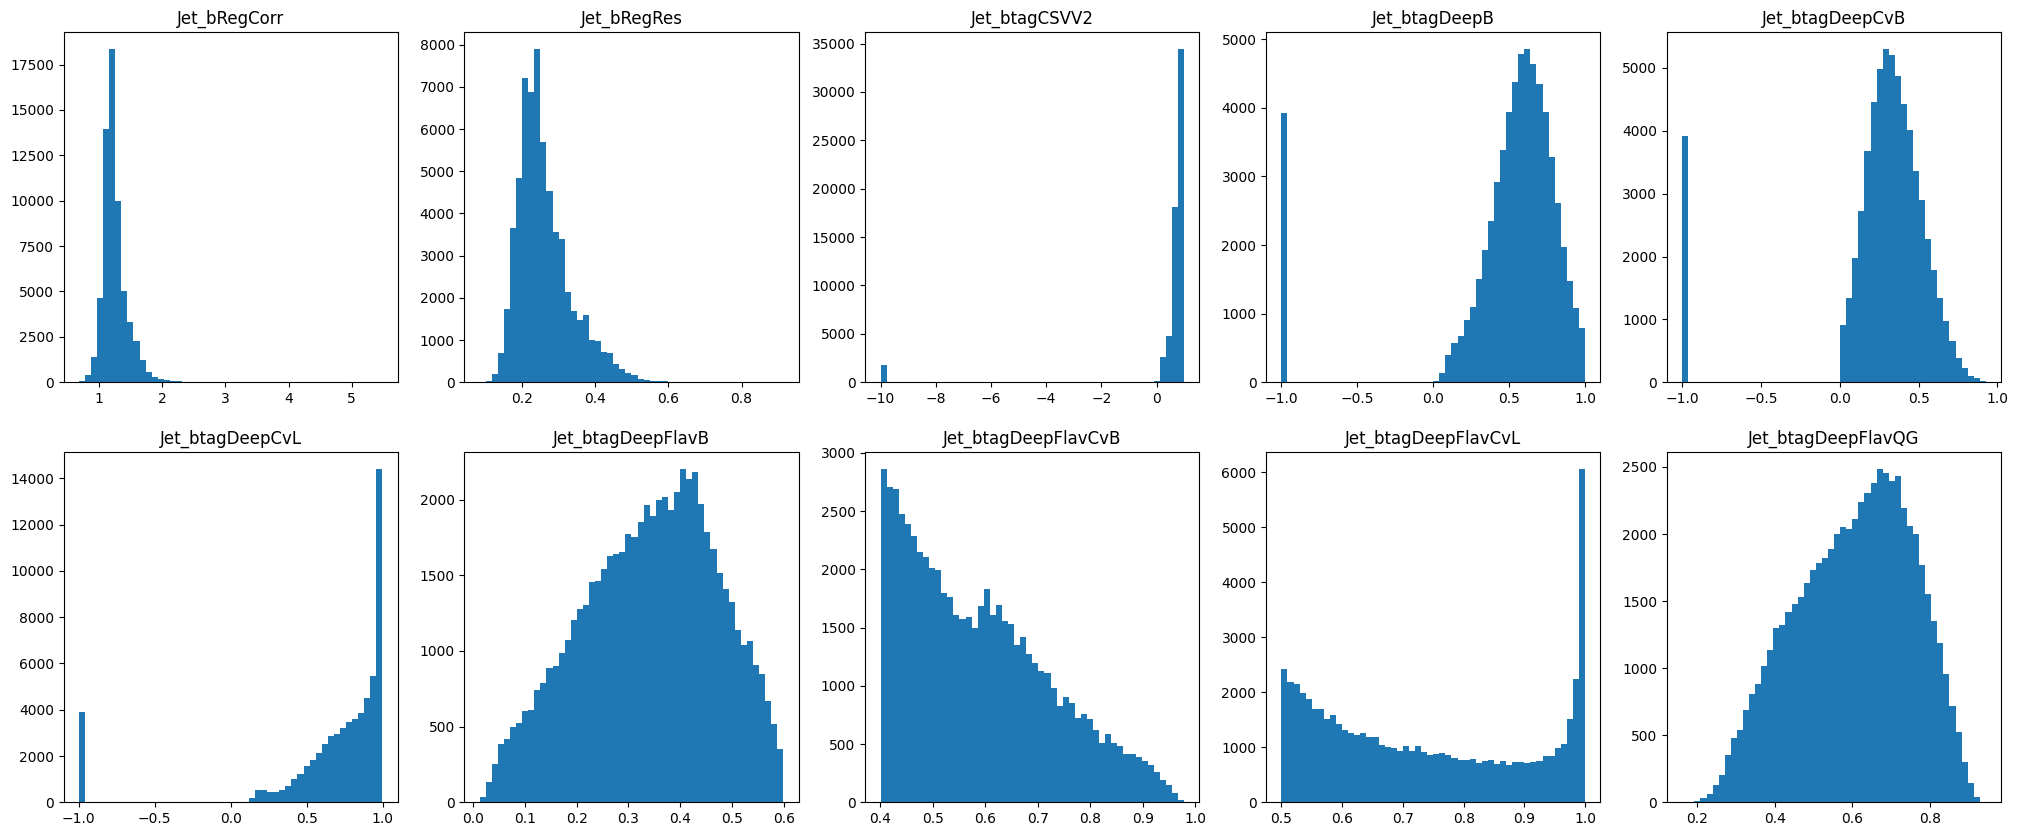

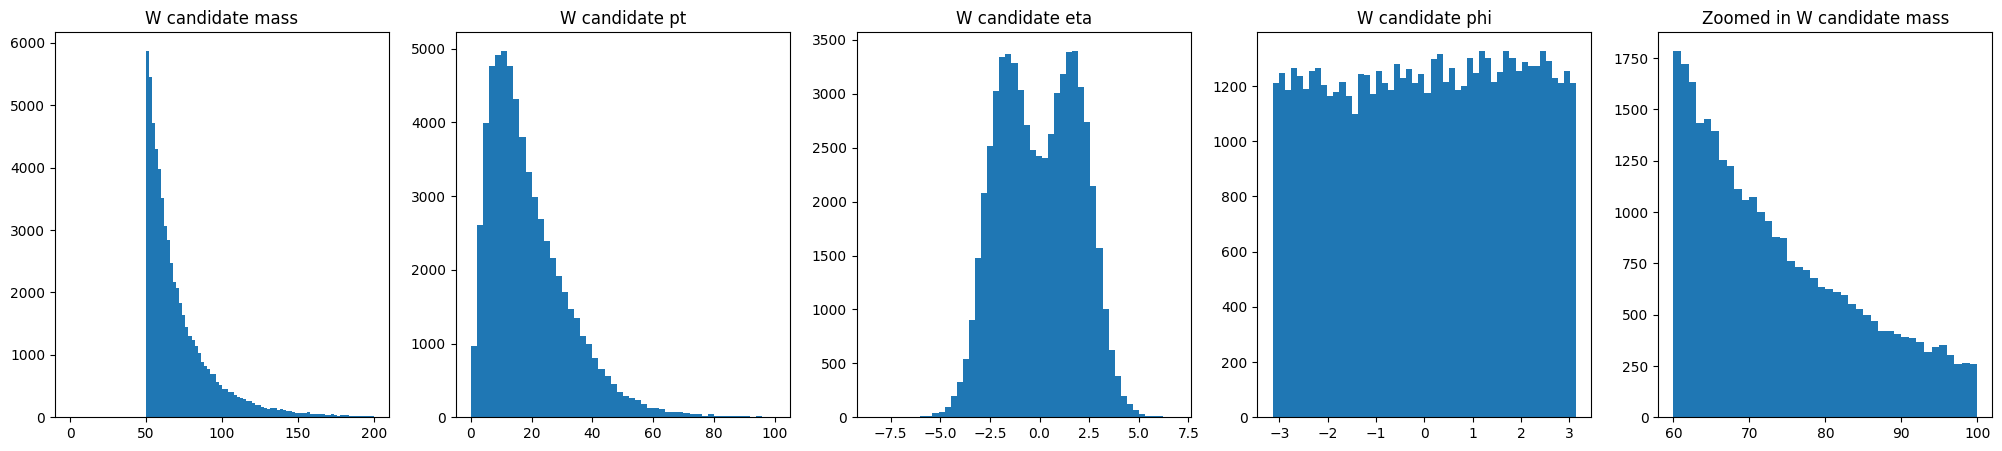

In [51]:
df1, desc1 = btag_req(df, "DeepFlavCvB", 0.4, 2)
df2, desc2 = btag_req(df1, "DeepFlavCvL", 0.5, 2)
desc = desc1 + ", " + desc2
full_hist(df2, desc)

0.004326521009811615
0.004830978923421067
0.005053648567049097 0.0036755151290142935


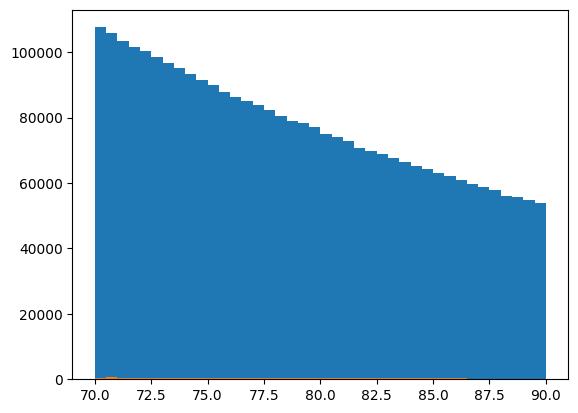

In [52]:
integral_1, a, b = integrate_hist(70,90,40,df)
integral_2, c, d = integrate_hist(70, 90, 40, df2)
iratio = integral_2/integral_1
print(iratio)
events1 = len(df)
events2 = len(df2)
eratio = events2/events1
print(eratio)
max1 = max(a)
max2= max(c)
maxratio = max2/max1
min1 = min(a)
min2 = min(c)
minratio = min2/min1
print(maxratio,minratio)

[ 2.17440146e+05 -3.86614472e-02 -6.81023406e+01  1.15823267e+04]
Ratio of exponential coefficient to total number of events:  0.03276883772145488
Ratio of exponential coefficient to highest number of events:  0.7019066317001095


C:\Users\avery\AppData\Local\Temp\ipykernel_30808\1496706186.py:5: RuntimeWarning: overflow encountered in exp
  expfit = lambda p, x: p[0]*np.exp(p[1]*(x+p[2]))+p[3]


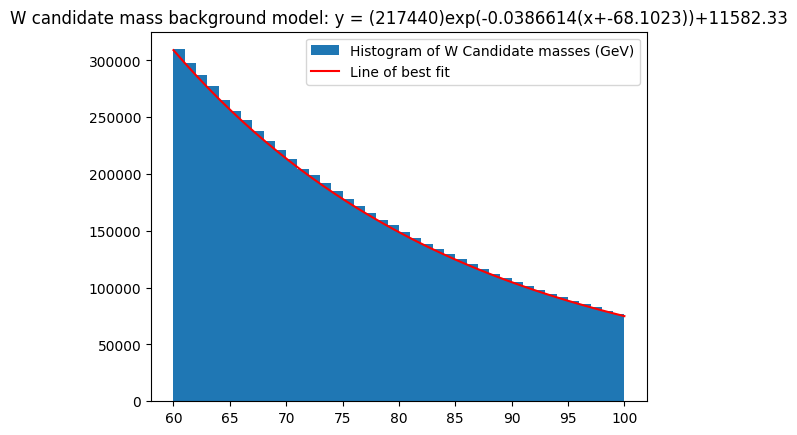

In [118]:
counts, edges, graph = plt.hist(df.wc_mass, bins = 40, range =(60,100), label = 'Histogram of W Candidate masses (GeV)')
x_vals = edges[:-1]
y_vals = counts

expfit = lambda p, x: p[0]*np.exp(p[1]*(x+p[2]))+p[3]
experr = lambda p, x, y: expfit(p,x)-y

p0 = [250000., -0.5, -70., 0.]
domain = np.linspace(60,100,40)
p1, success = optimize.leastsq(experr, p0[:], args = (x_vals, y_vals))
plt.plot(domain, expfit(p1,domain), 'r-', label = f'Line of best fit')
plt.title(f'W candidate mass background model: y = ({p1[0]:.0f})exp({p1[1]:.7f}(x+{p1[2]:.4f}))+{p1[3]:.2f}')
plt.legend()
print(p1)


print("Ratio of exponential coefficient to total number of events: ",p1[0]/sum(counts))
print("Ratio of exponential coefficient to highest number of events: ", p1[0]/max(counts))

jpsi pt vs jet pt

set range

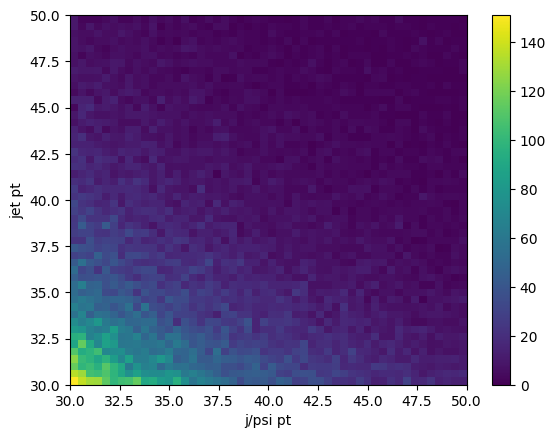

In [ ]:
plt.hist2d(df2['jpsi_pt'], df2['Jet_pt'], range= [[30,50],[30,50]], bins=[50,50])
plt.xlabel('j/psi pt')
plt.ylabel('jet pt')
plt.colorbar()


Exponential fit works for full range, but polynomial is better for the range around 80

[np.float64(1050.4487619543877), np.float64(-0.03866144724434955), np.float64(-68.1023406265378), np.float64(55.95397612399296)]
[np.float64(940.7593596181243), np.float64(-0.03866144724434955), np.float64(-68.1023406265378), np.float64(50.111179767168046)] [ 5.30842721e+08 -4.95110625e-01  4.18673463e+03  7.68175000e+02]
Ratio of exponential coefficient to total number of events:  17276.099888514364
Ratio of exponential coefficient to highest number of events:  297224.3680147709


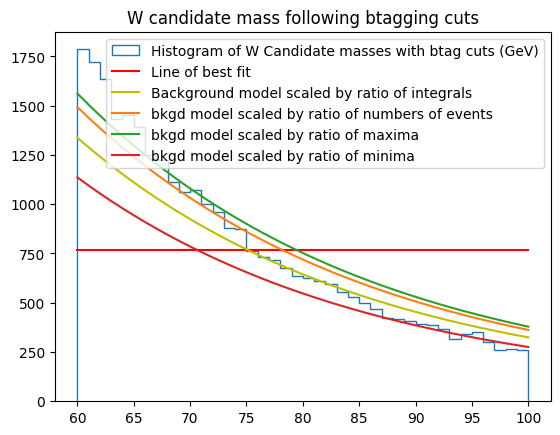

In [119]:
counts, edges, graph = plt.hist(df2.wc_mass, bins = 40, range =(60,100), label = 'Histogram of W Candidate masses with btag cuts (GeV)', histtype = 'step')
x_vals_c = edges[:-1] # cut vers of x vals
y_vals_c = counts #cut vers of y vals

expfit = lambda p, x: p[0]*np.exp(p[1]*(x+p[2]))+p[3]
experr = lambda p, x, y: expfit(p,x)-y

p0 = [250000., -0.5, -60., 0.]
p1_sc = scale_p_by(p1, iratio)
p1_esc = scale_p_by(p1, eratio)
p1_maxsc = scale_p_by(p1,maxratio)
p1_minsc = scale_p_by(p1,minratio)
domain = np.linspace(60,100,40)
print(p1_esc)
func = 250000*np.exp(-0.5*(domain-60))
p2, success = optimize.leastsq(experr, p0[:], args = (x_vals_c, y_vals_c))
plt.plot(domain, expfit(p2,domain), 'r-', label = f'Line of best fit')
plt.plot(domain, expfit(p1_sc, domain), 'y-', label = 'Background model scaled by ratio of integrals')
plt.plot(domain, expfit(p1_esc,domain), label = 'bkgd model scaled by ratio of numbers of events')
plt.plot(domain, expfit(p1_maxsc,domain), label = 'bkgd model scaled by ratio of maxima')
plt.plot(domain, expfit(p1_minsc,domain), label = 'bkgd model scaled by ratio of minima')
plt.title('W candidate mass following btagging cuts')
plt.legend()
print(p1_sc, p2)
print("Ratio of exponential coefficient to total number of events: ",p2[0]/sum(counts))
print("Ratio of exponential coefficient to highest number of events: ", p2[0]/max(counts))

curve fit background for small window around 80

[ 5.01959190e+01 -1.07420928e+04  6.13334442e+05]


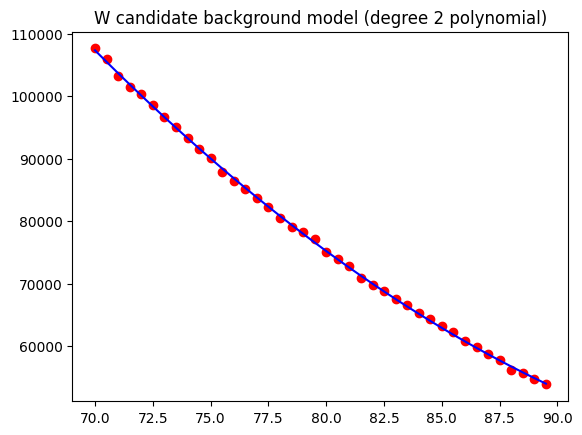

In [57]:
p1 = np.polyfit(x_vals, y_vals, deg = 2)
fit_line = p1[0]*x_vals**2+p1[1]*x_vals+p1[2]
plt.plot(x_vals,y_vals,'ro',x_vals, fit_line, 'b-')
plt.title("W candidate background model (degree 2 polynomial)")
print(p1)

[ 1.00472041e+00 -1.95871277e+02  9.85597833e+03]


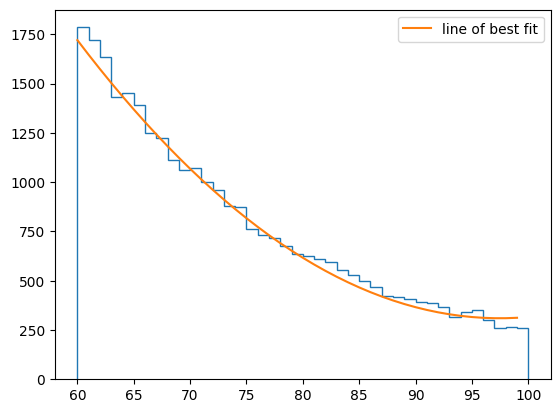

In [122]:

#poly_p_isc = [p1[0]*iratio,p1[1]*iratio,p1[2]*iratio]
poly_eq = lambda p, x: p[0]*x**2+p[1]*x+p[2]
p2 = np.polyfit(x_vals_c, y_vals_c, deg = 2)
plt.hist(df2.wc_mass, bins = 40, range = (60,100), histtype = 'step')
#plt.plot(x_vals, poly_eq(poly_p_isc,x_vals), label = 'scaled background line by ratio of integrals')
plt.plot(x_vals_c, poly_eq(p2,x_vals_c), label = 'line of best fit')
plt.legend()
print(p2)

can drop jpsi and muon plots

jet mass in range: 1.8 to 4, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


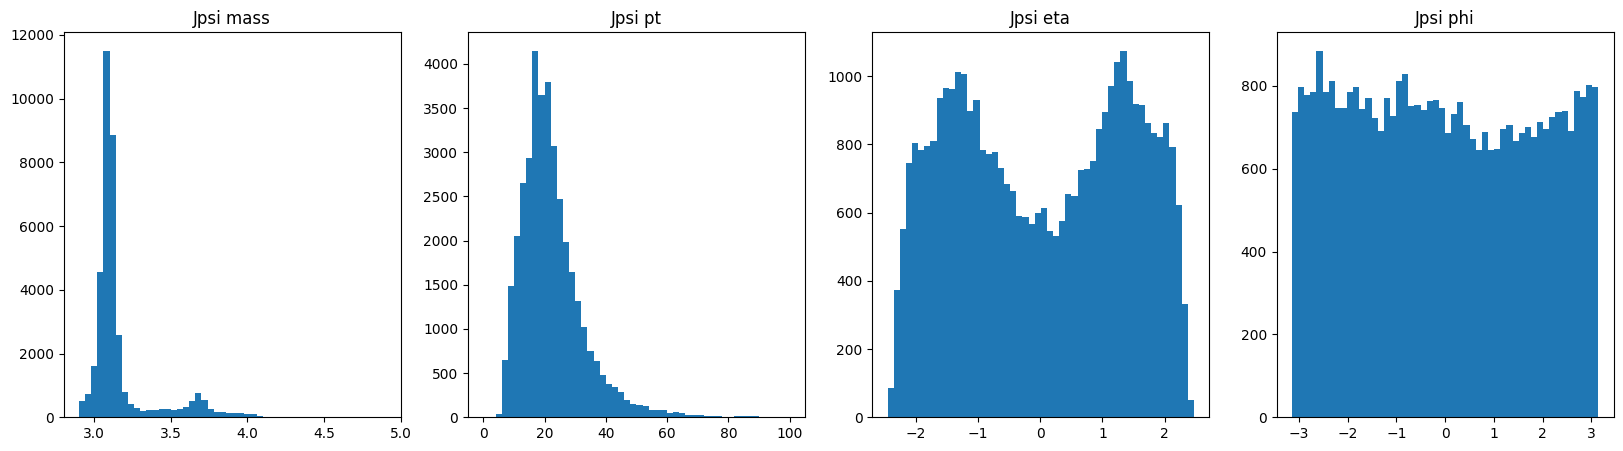

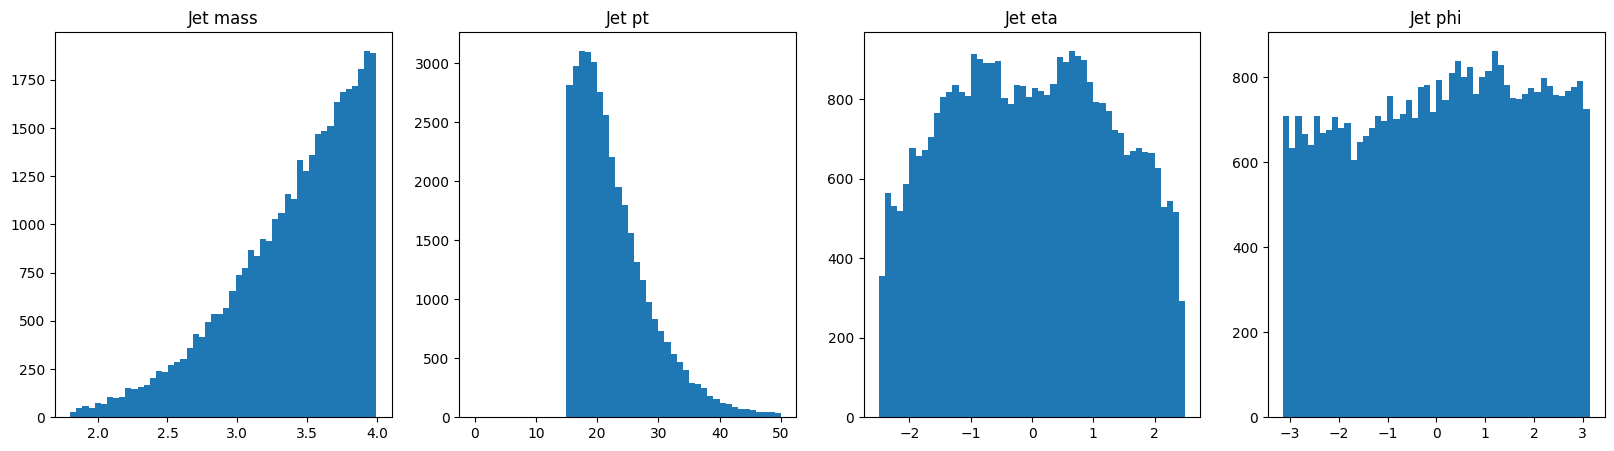

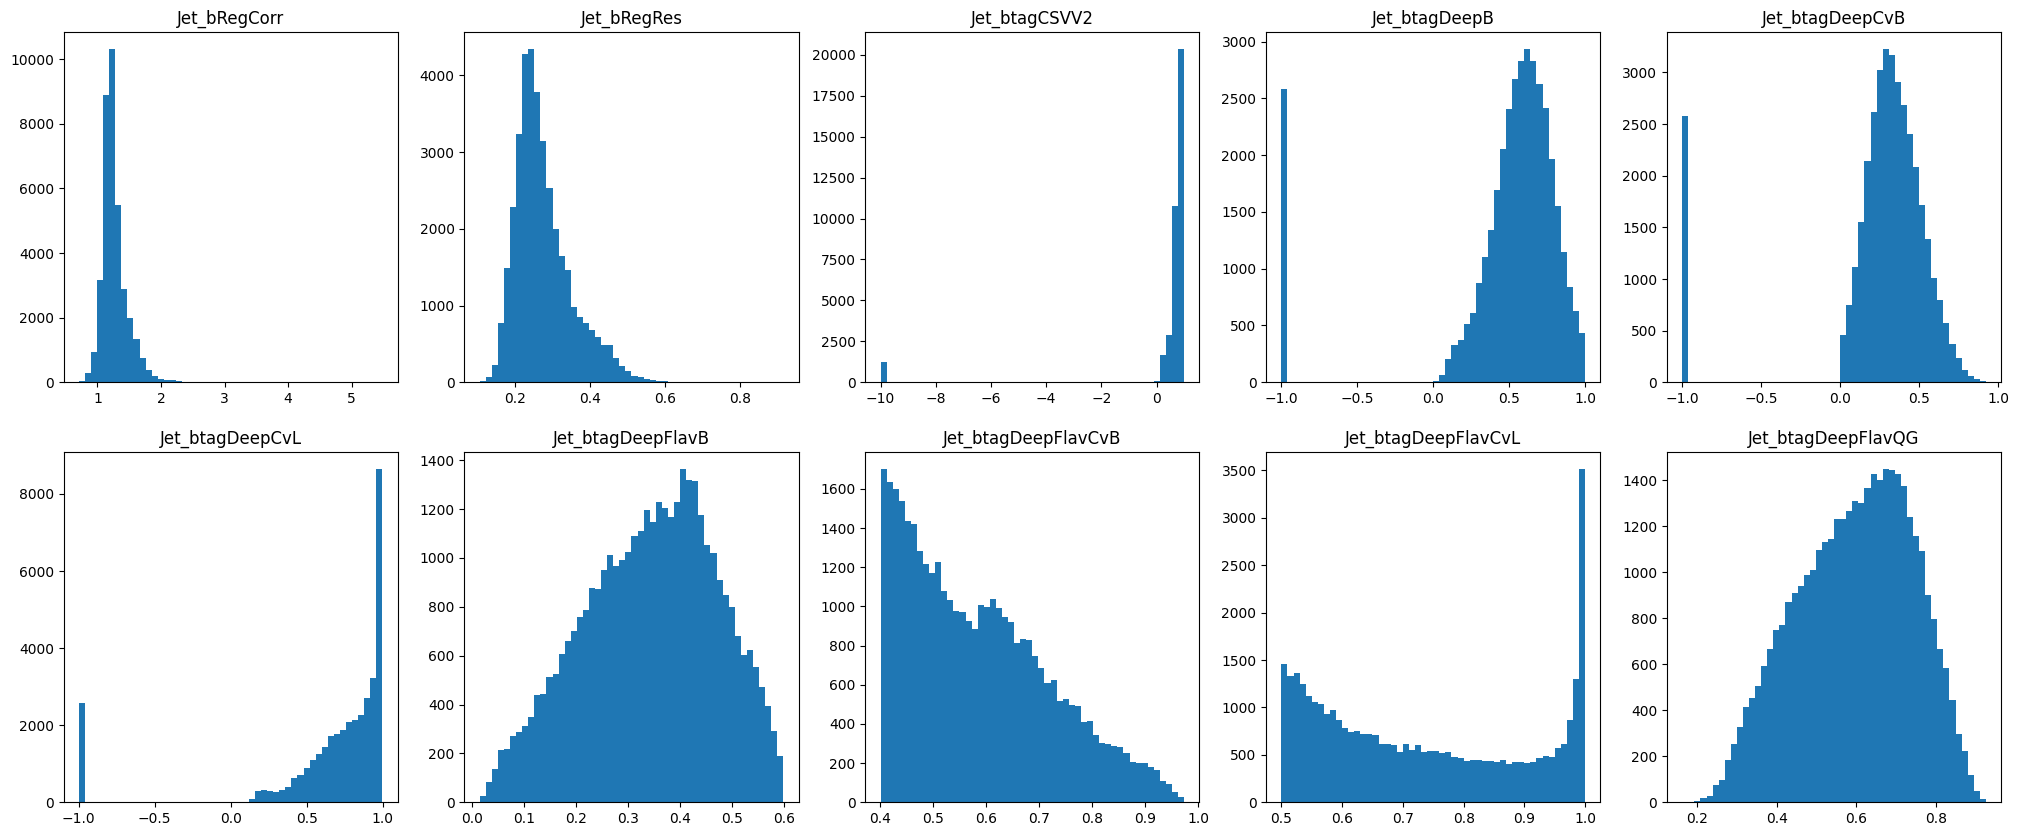

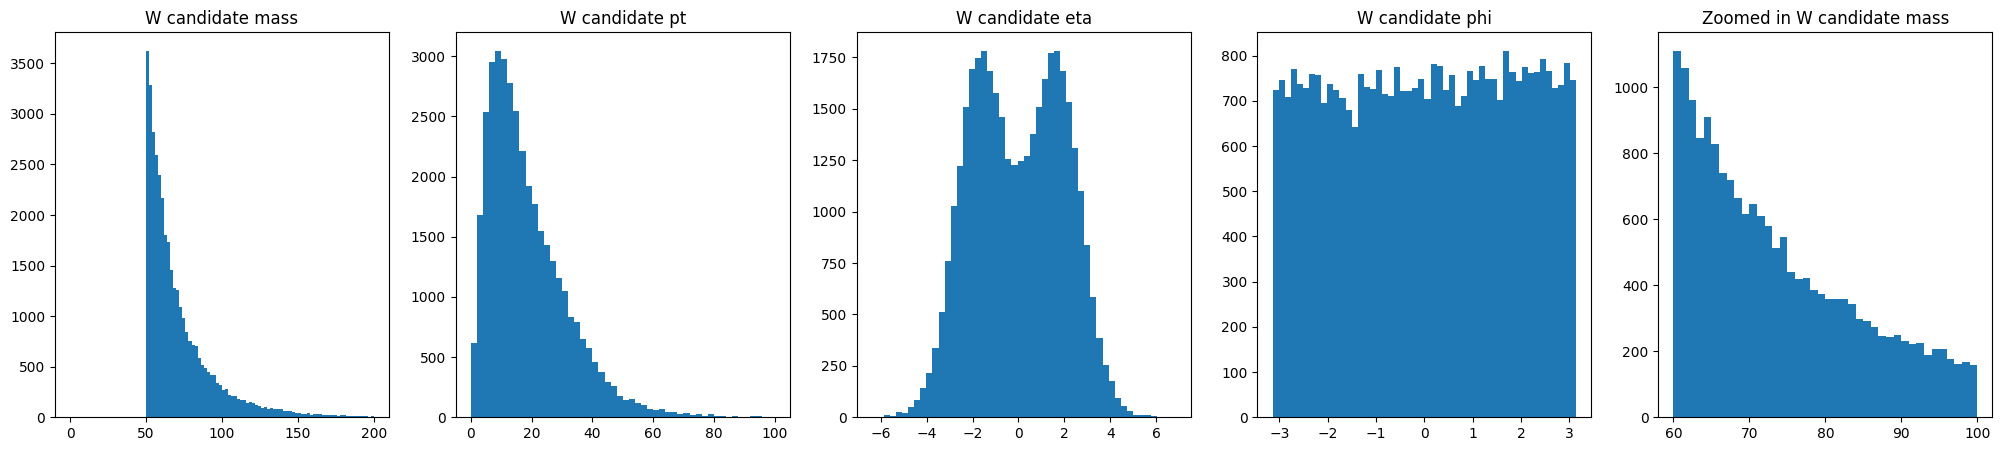

In [59]:
df3, desc3 = jet_req(df2, 1.8, 4)
desc4 = desc3 + ", " + desc
full_hist(df3, desc4)

jpsi mass within range 0 to 3.3, jet mass in range: 1.8 to 4, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


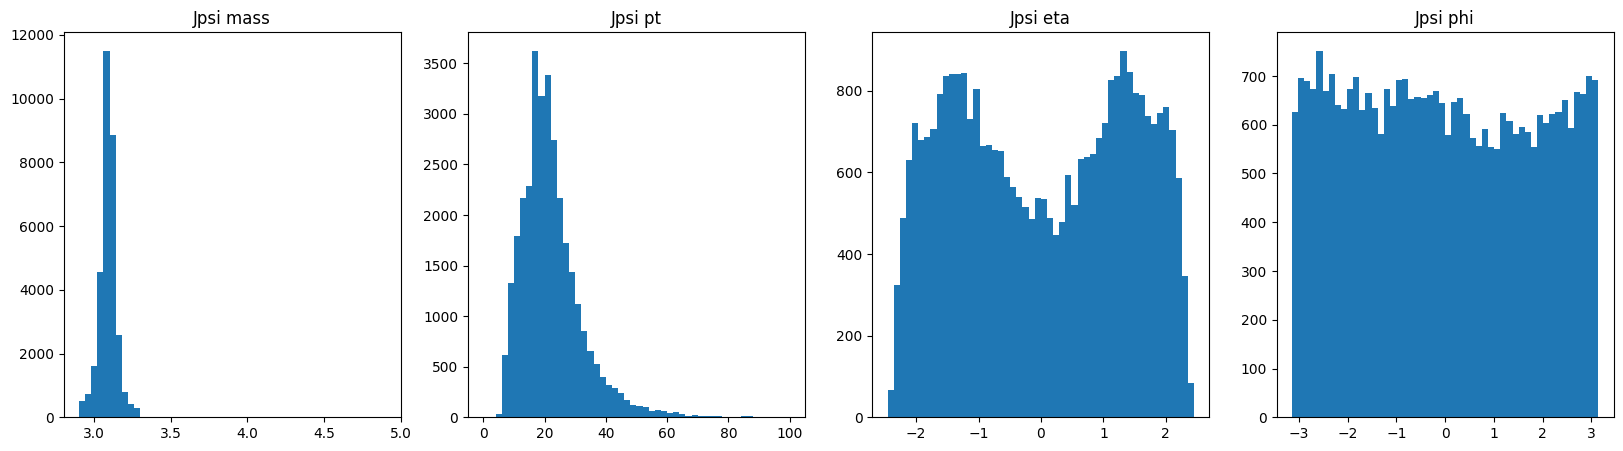

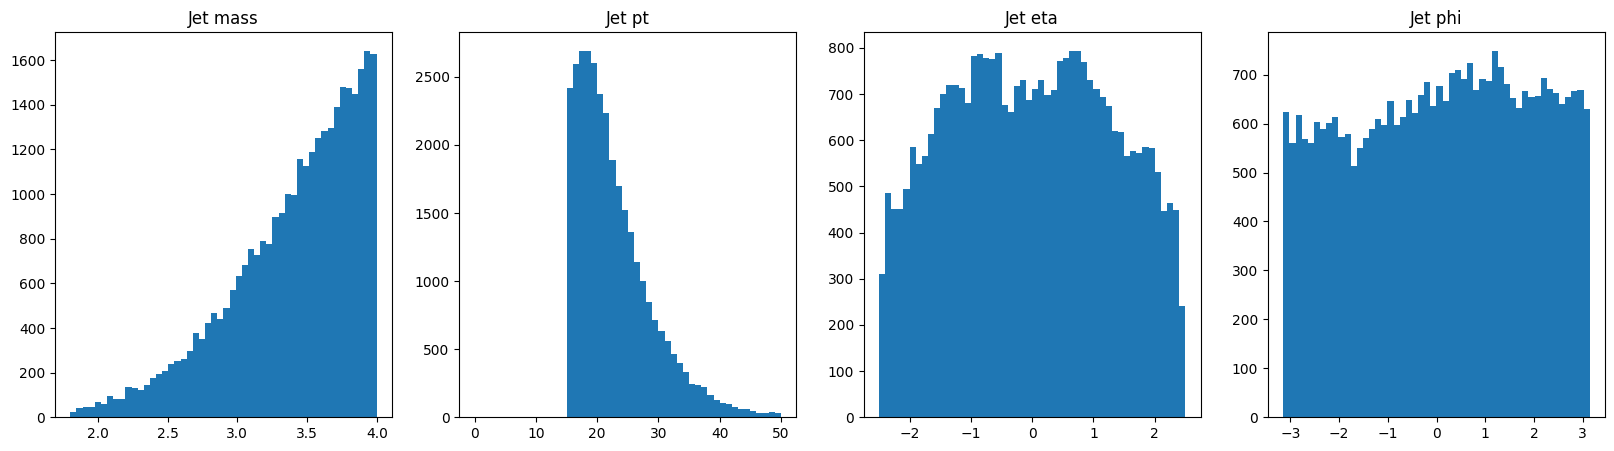

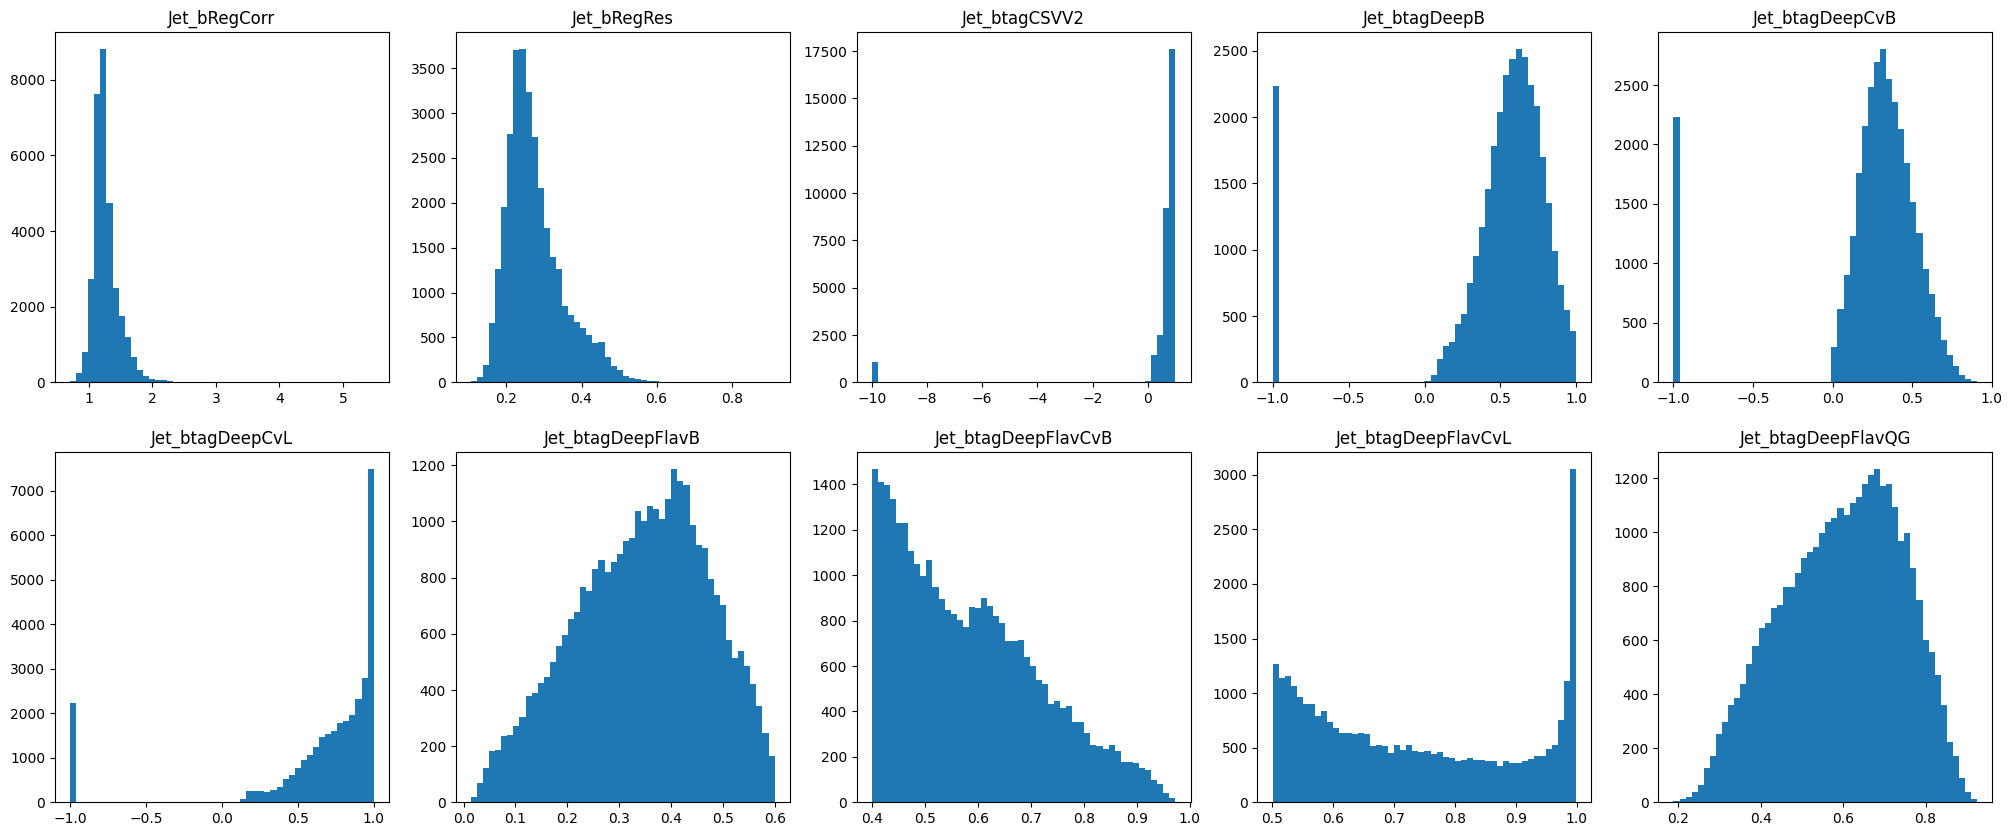

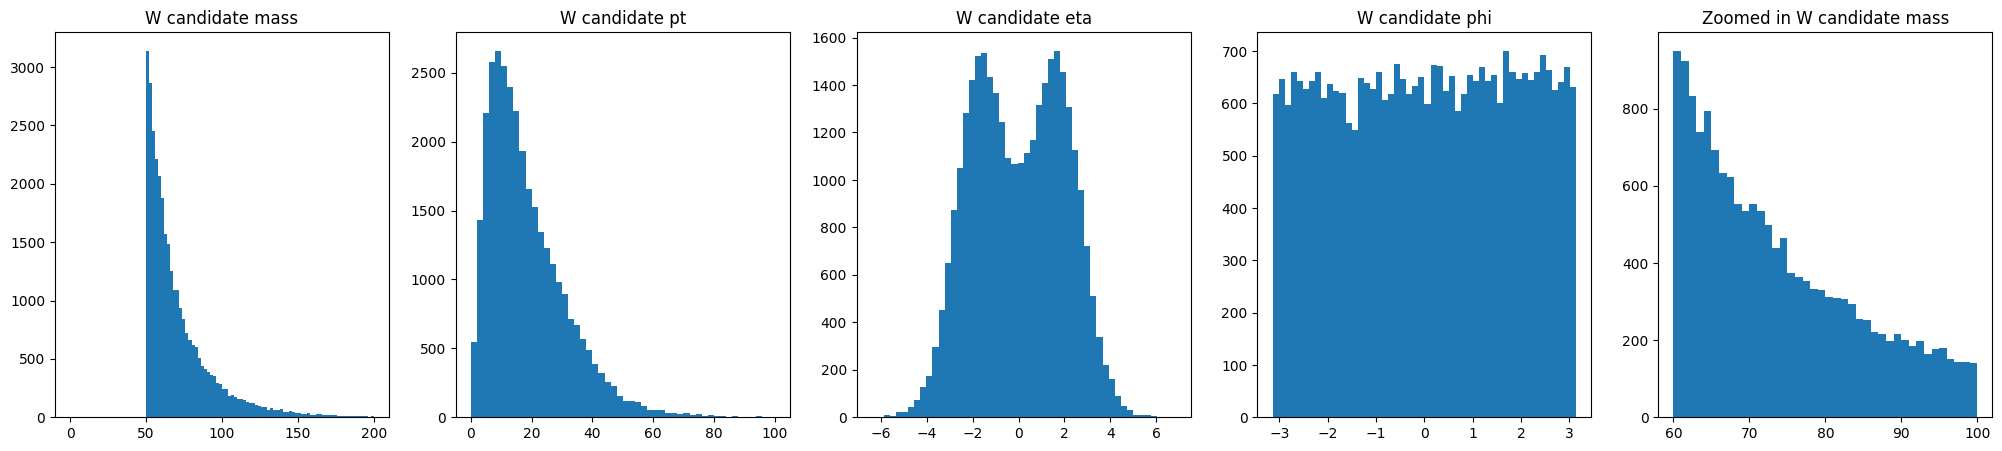

In [94]:
jpsi_df, jpsi_desc = jpsi_in(df3, 0, 3.3)
jpsi_desc += ', '+desc4
full_hist(jpsi_df,jpsi_desc)

Jet_btagDeepFlavCvB in range: 0.6 to 2, jet mass in range: 1.8 to 4, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


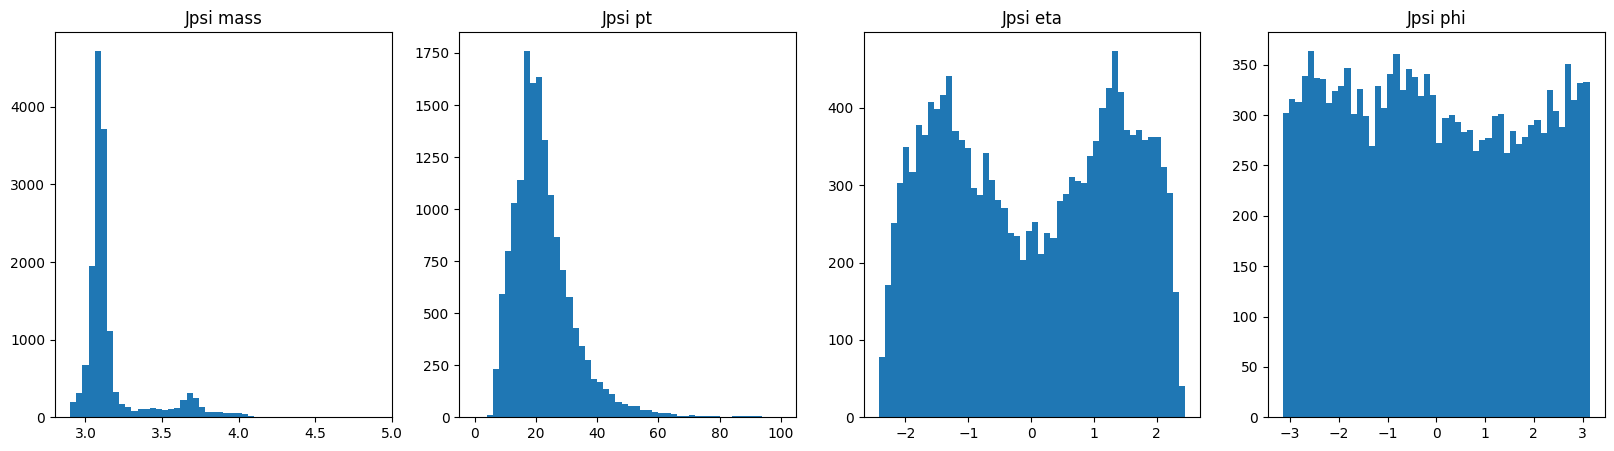

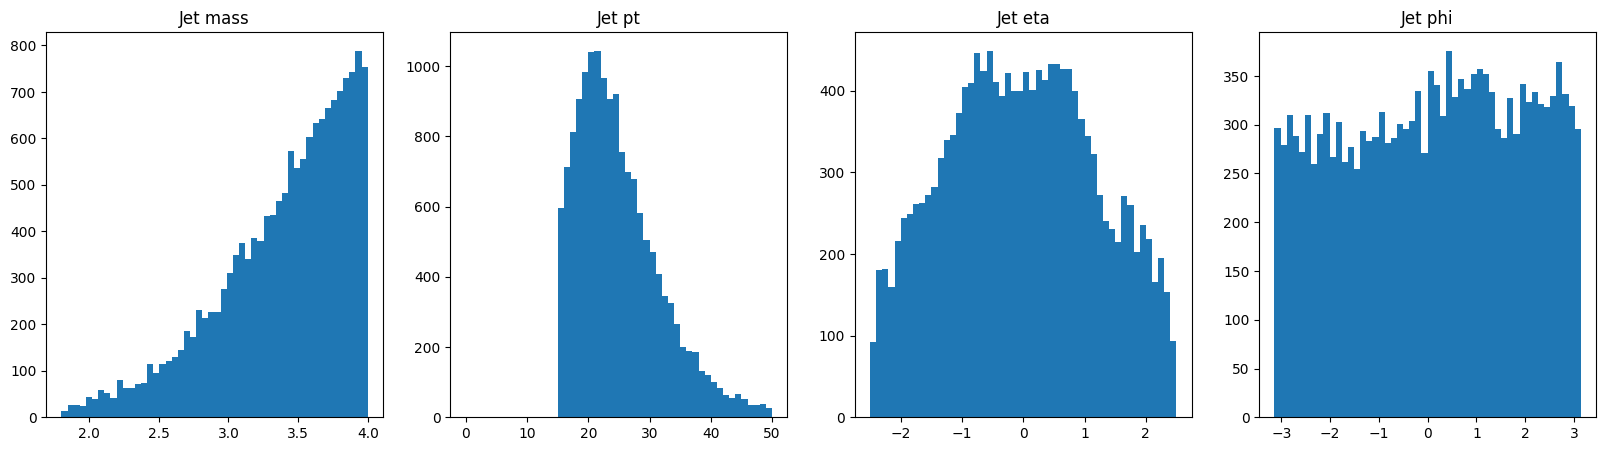

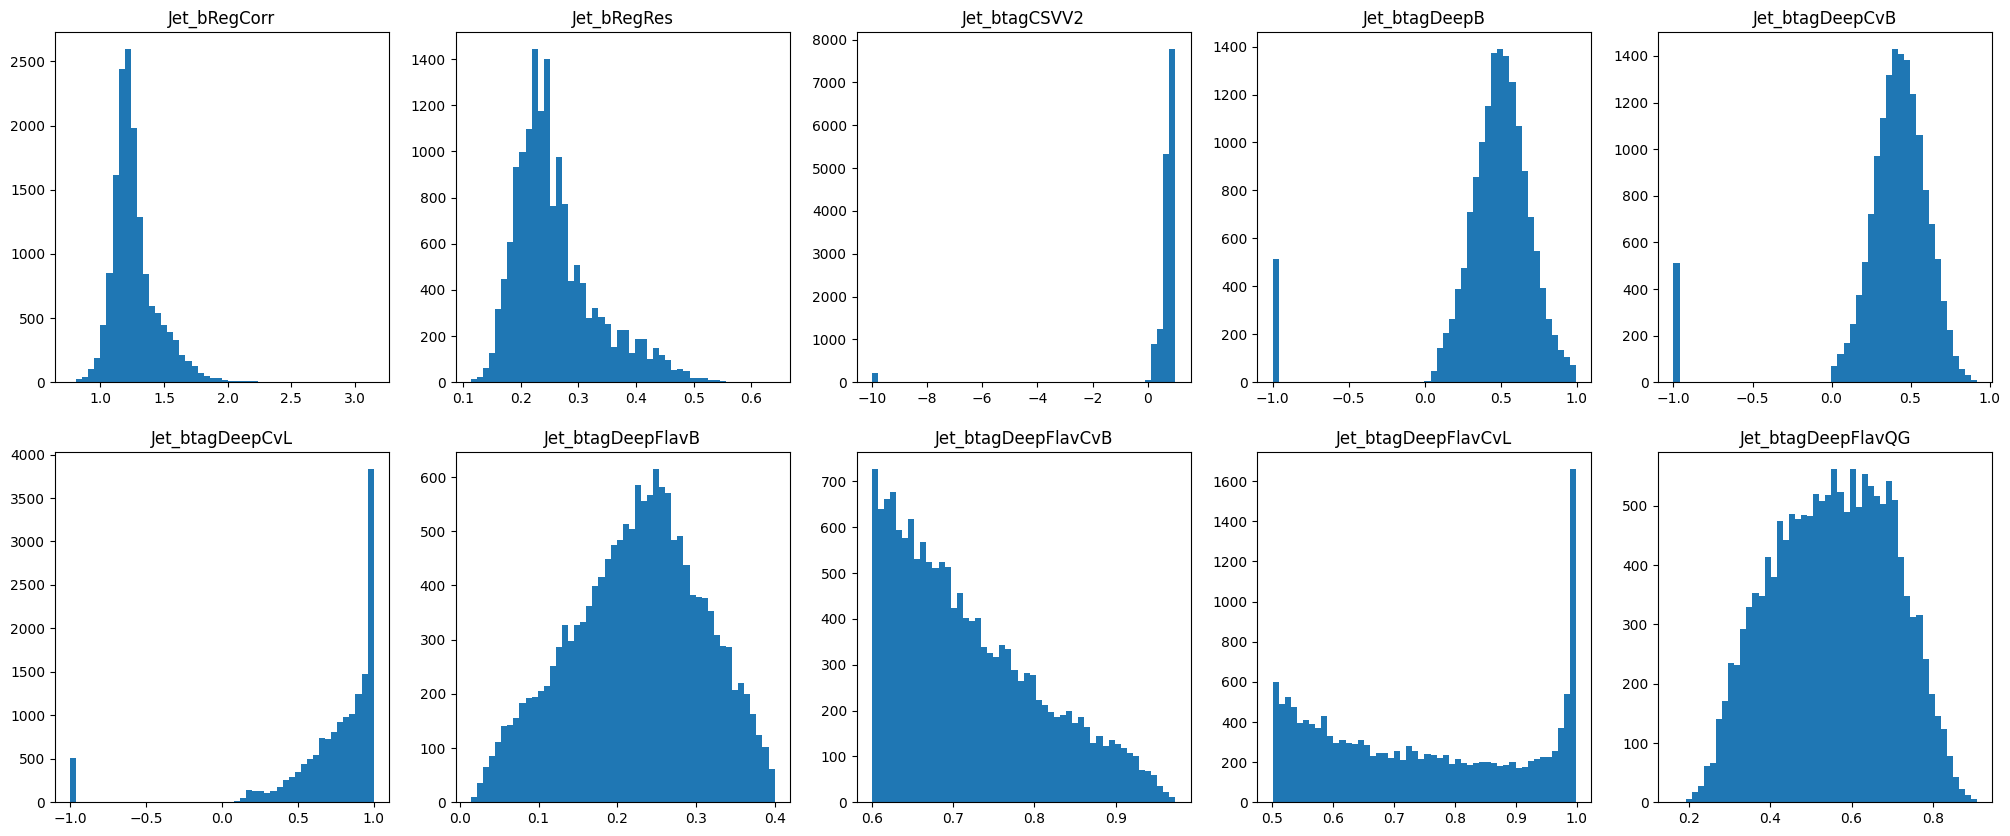

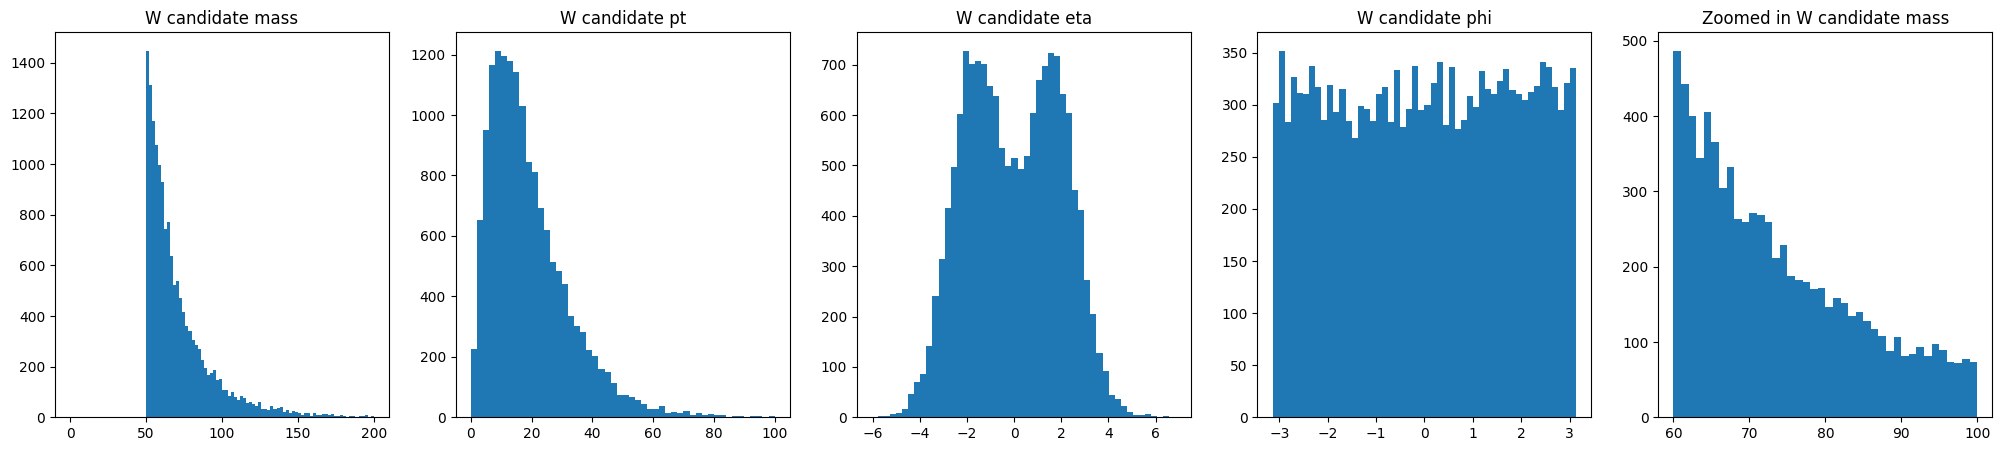

In [61]:
jet_df1, jet_desc1 = btag_req(df3, "DeepFlavCvB", 0.6, 2)
jet_desc1 += ", " + desc4
full_hist(jet_df1, jet_desc1)

jpsi mass within range 0 to 3.3, Jet_btagDeepFlavCvB in range: 0.6 to 2, jet mass in range: 1.8 to 4, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


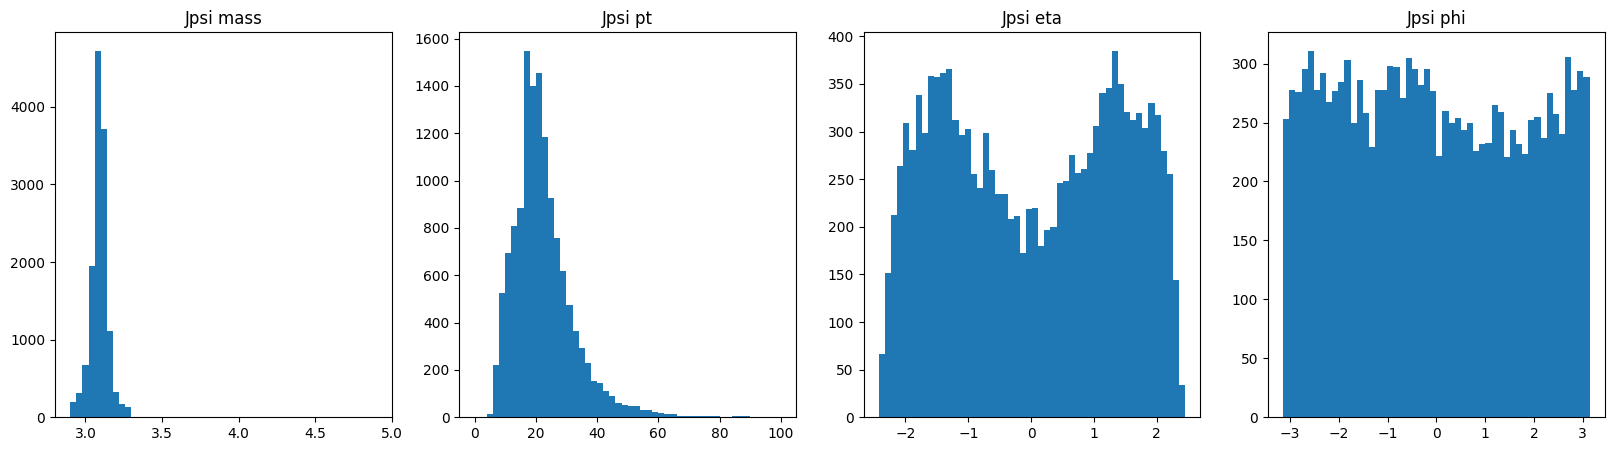

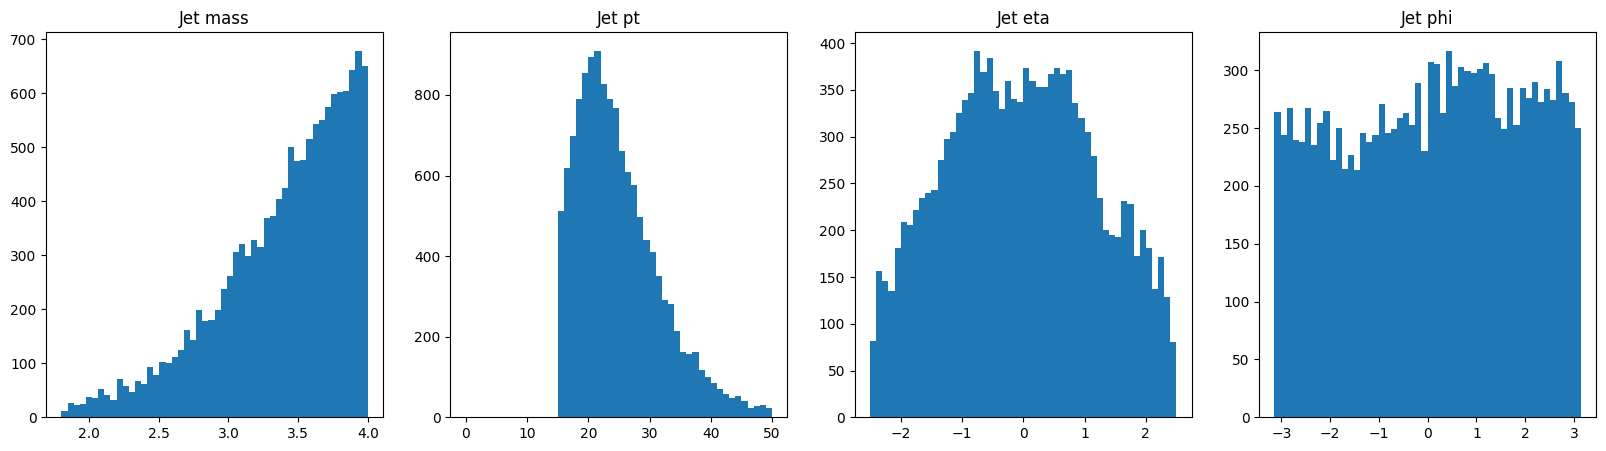

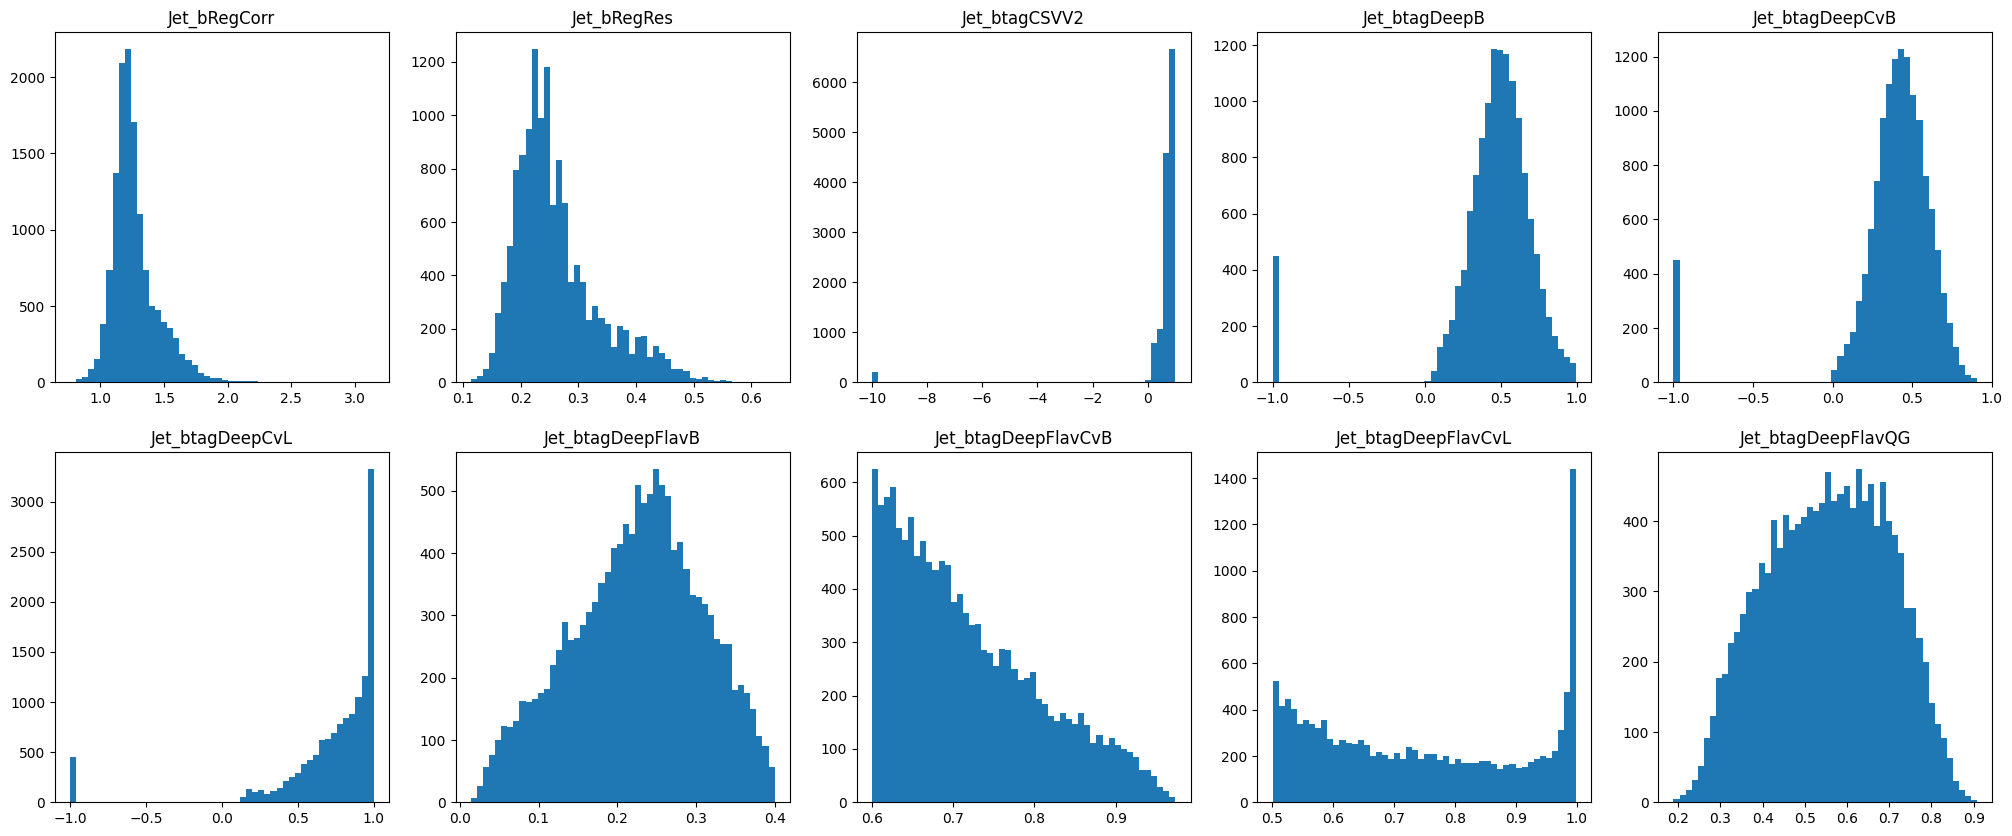

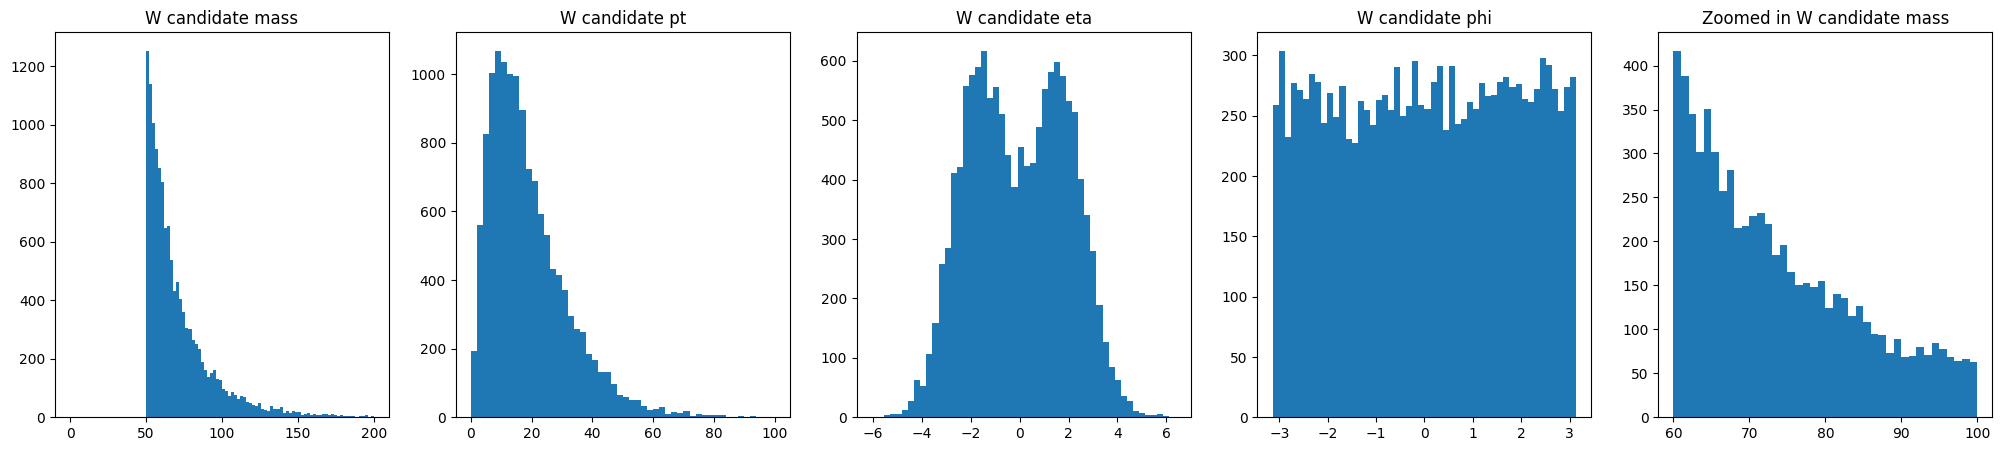

In [96]:
jpsi_df, jpsi_desc = jpsi_in(jet_df1, 0, 3.3)
jpsi_desc += ', '+jet_desc1
full_hist(jpsi_df,jpsi_desc)

jet mass in range: 1.8 to 3.5, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


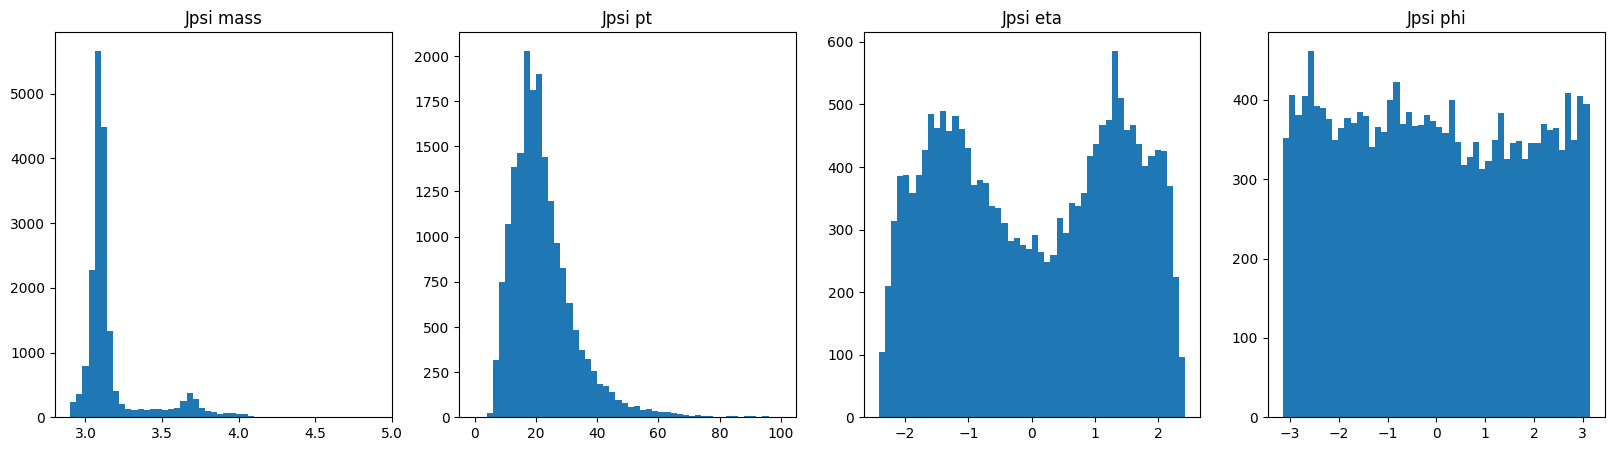

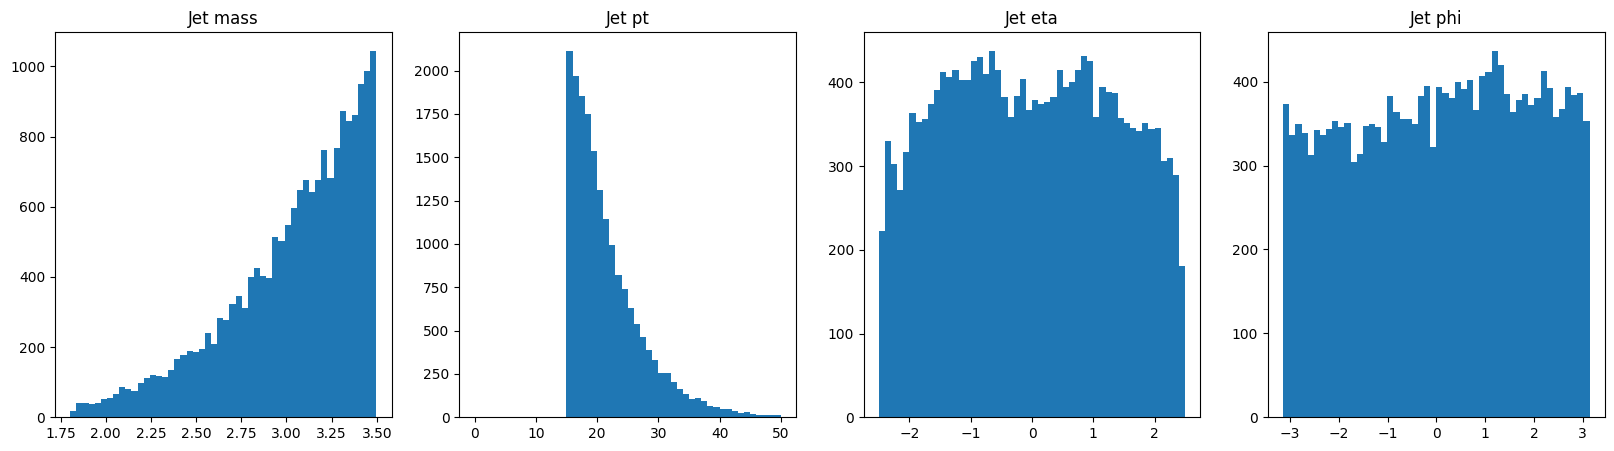

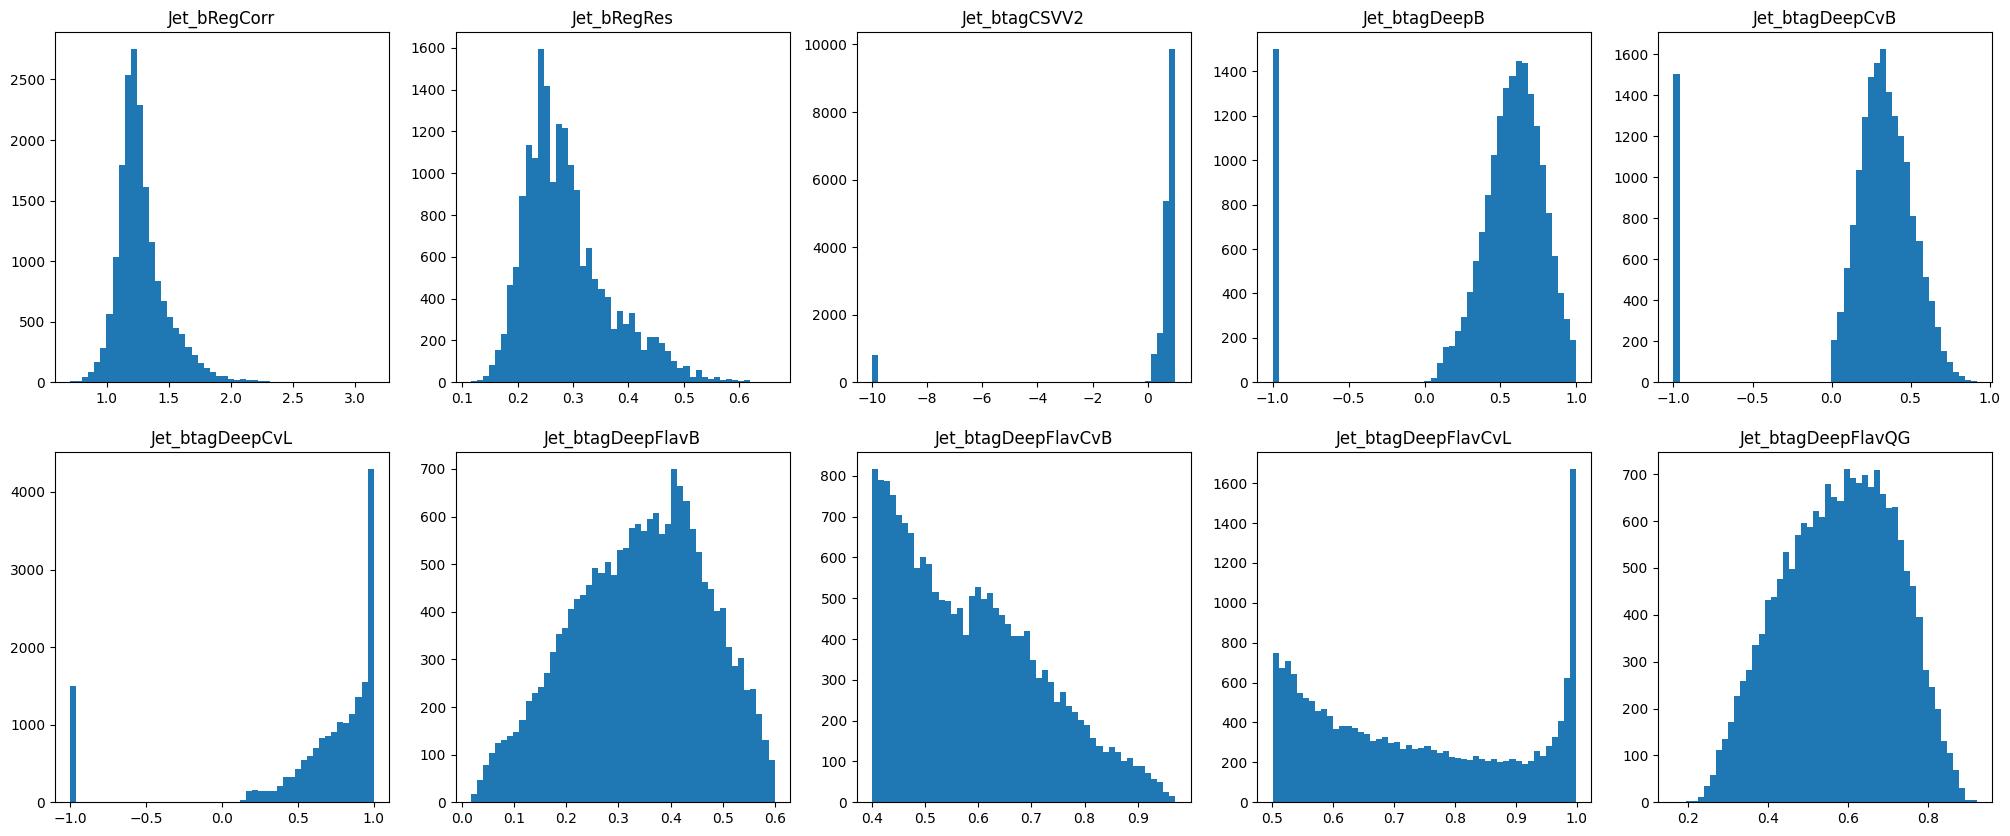

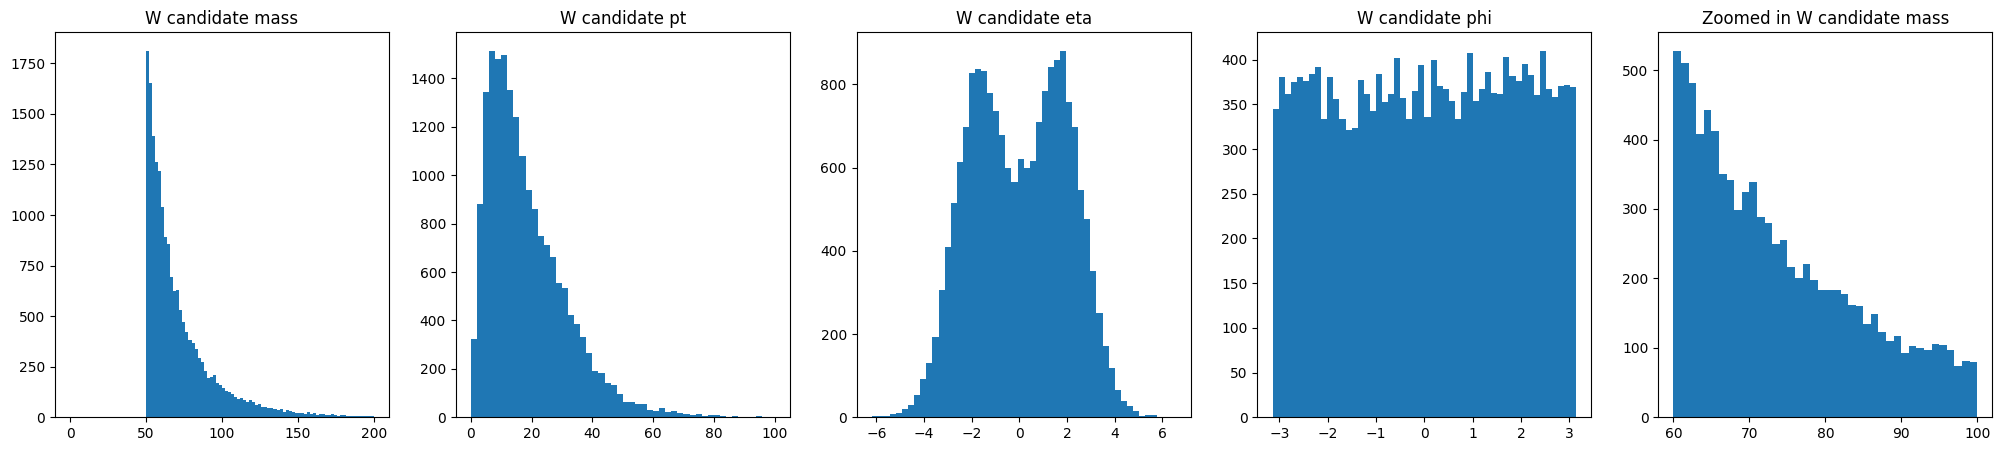

In [63]:
df5, desc5 = jet_req(df2, 1.8, 3.5)
desc5+= ", " + desc
full_hist(df5, desc5)

jpsi mass within range 0 to 3.3, jet mass in range: 1.8 to 3.5, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


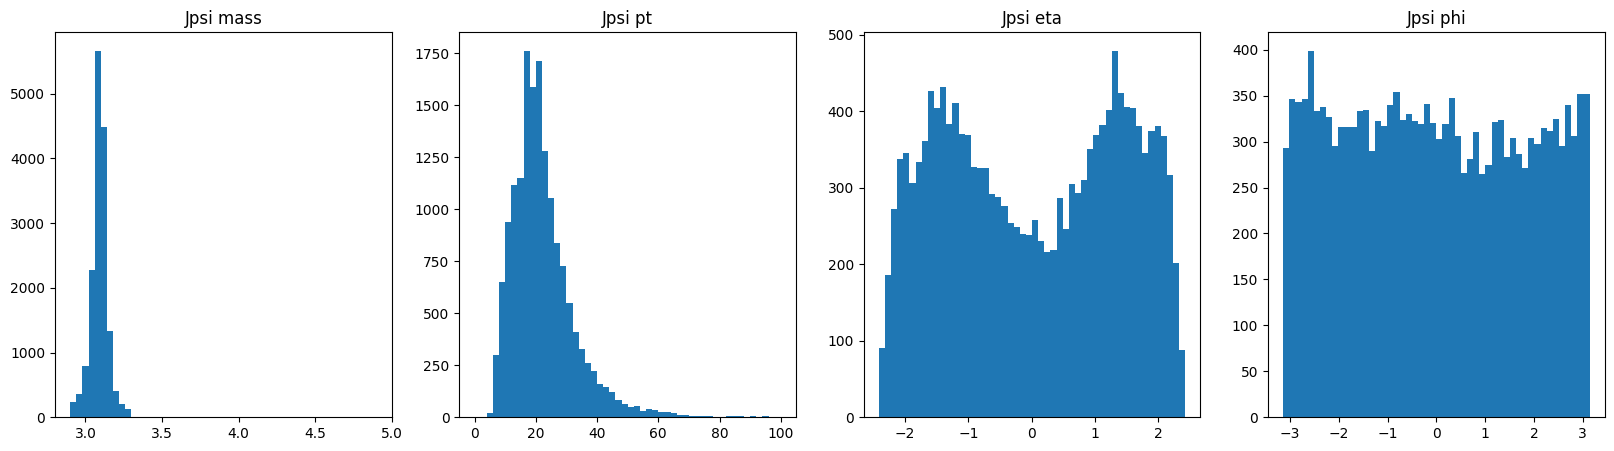

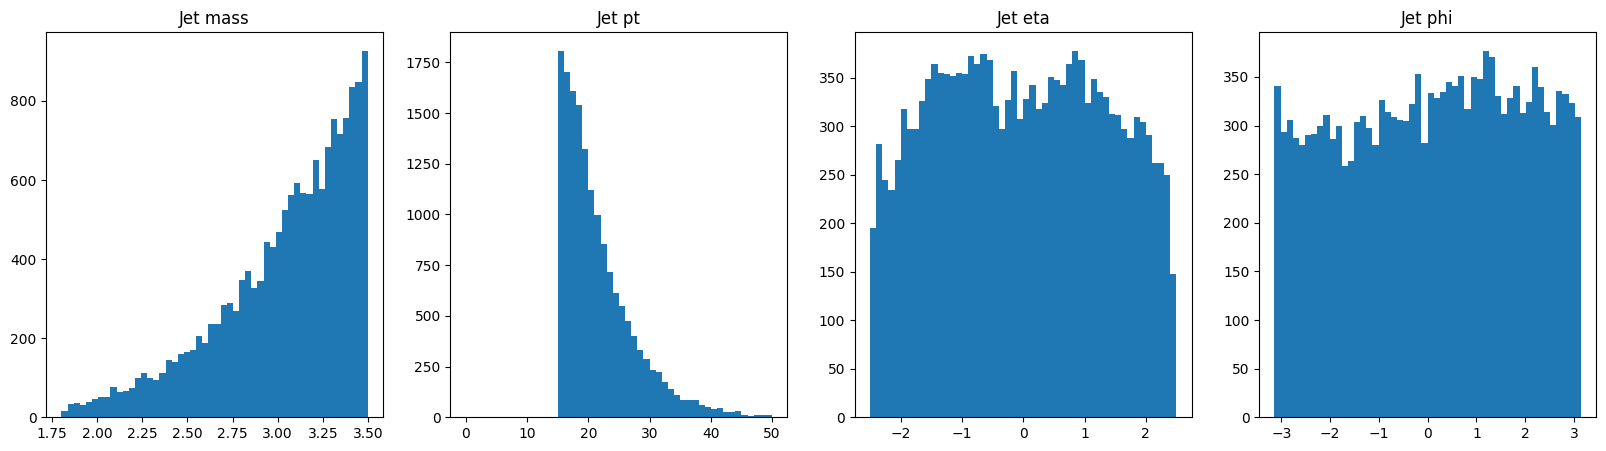

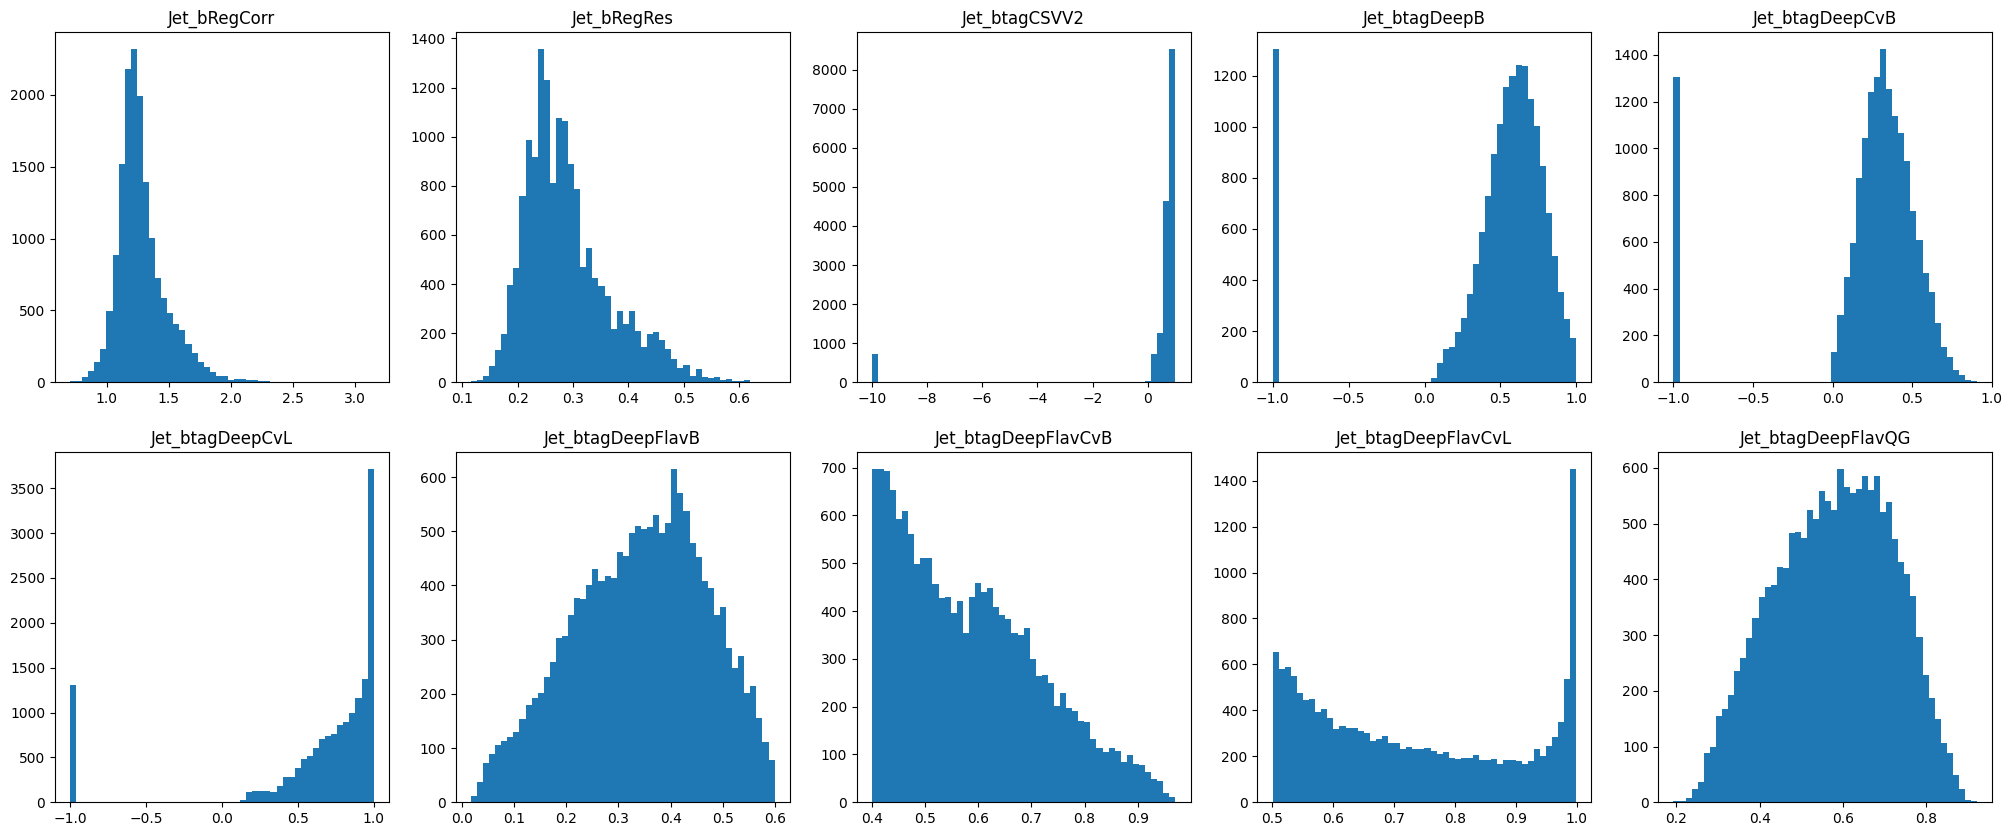

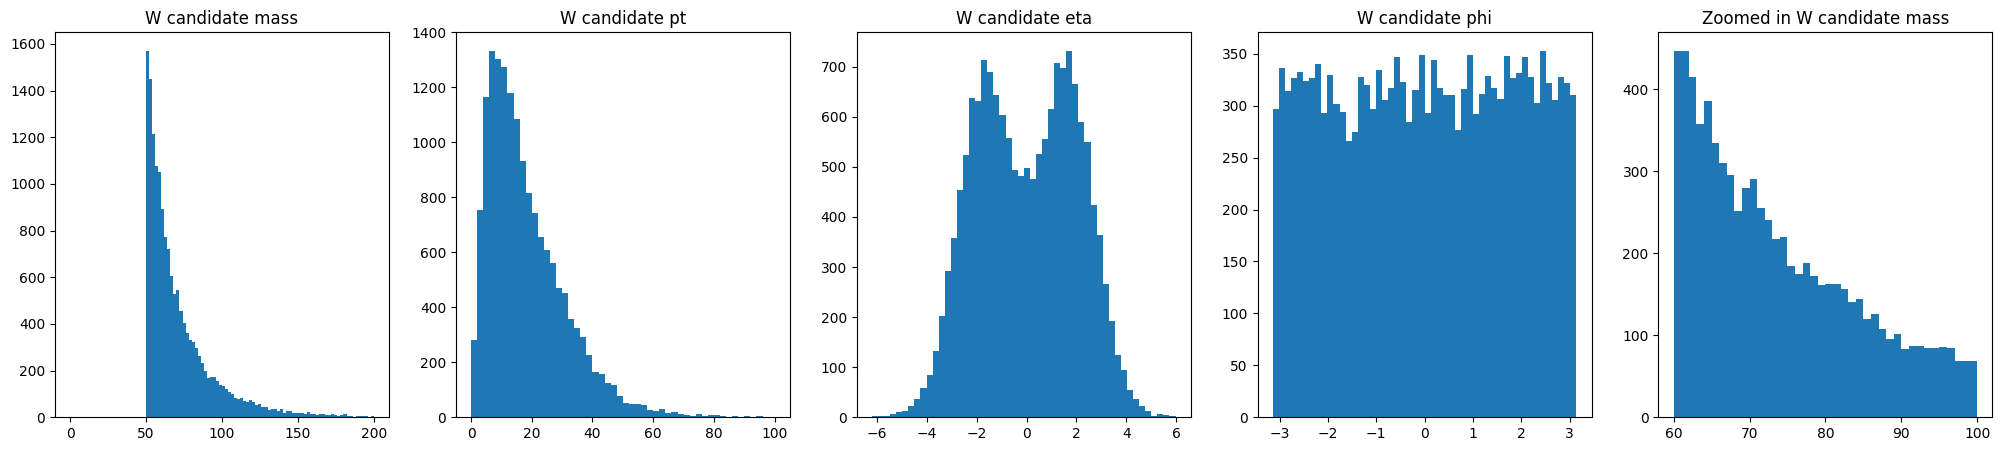

In [95]:
jpsi_df, jpsi_desc = jpsi_in(df5, 0, 3.3)
jpsi_desc += ', '+desc5
full_hist(jpsi_df,jpsi_desc)

Jet_btagDeepFlavCvB in range: 0.6 to 2, jet mass in range: 1.8 to 3.5, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


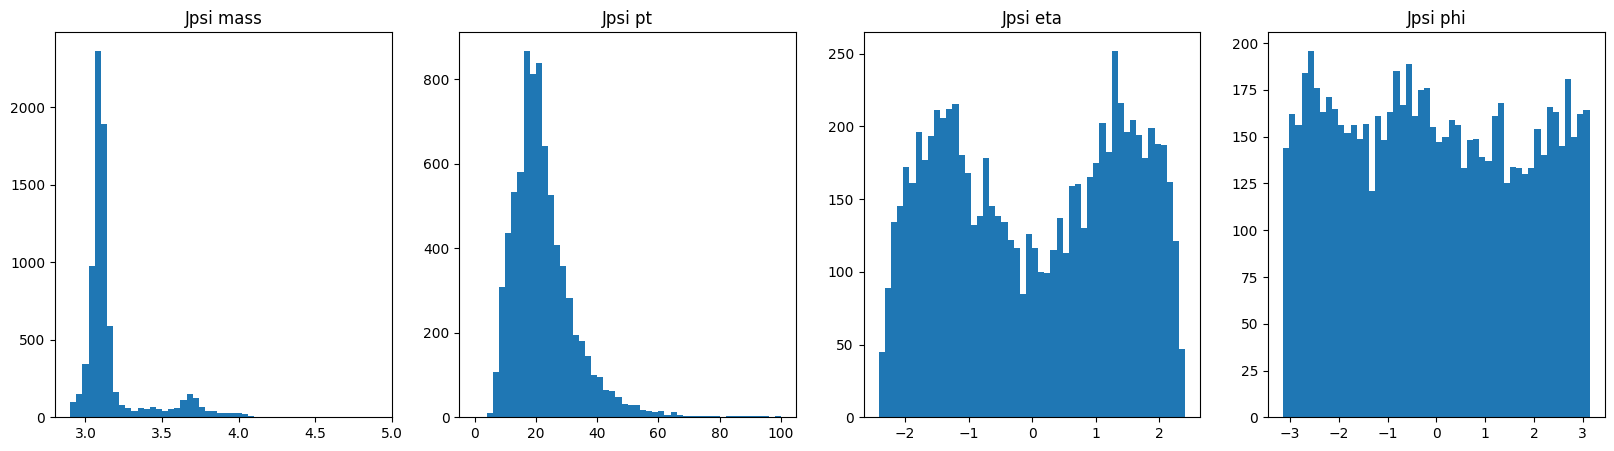

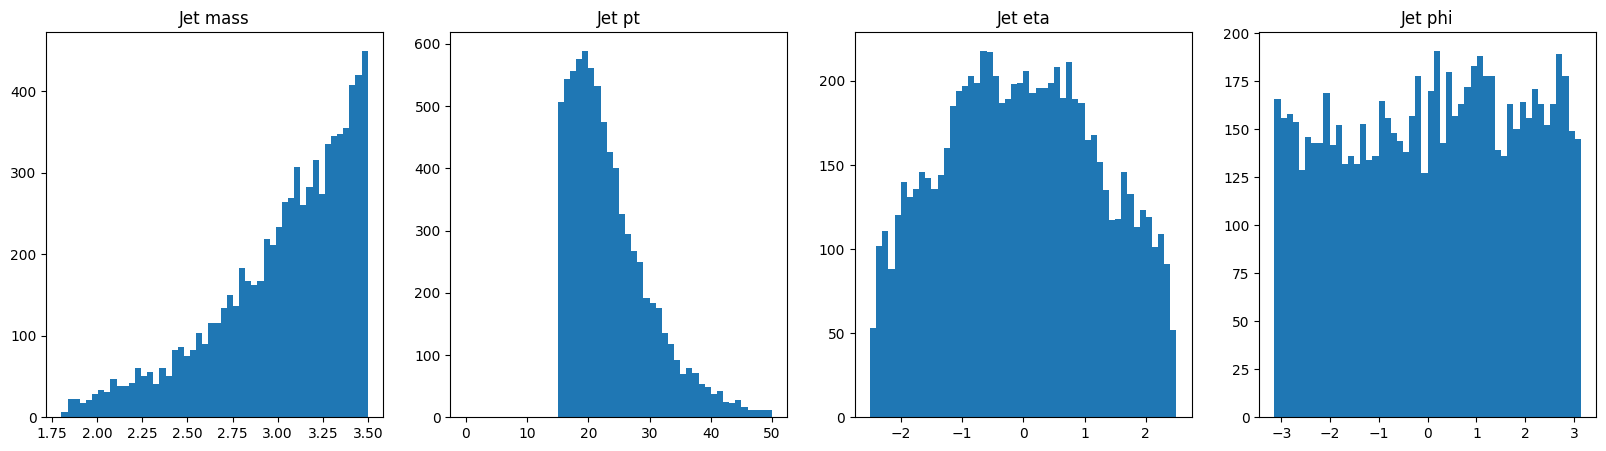

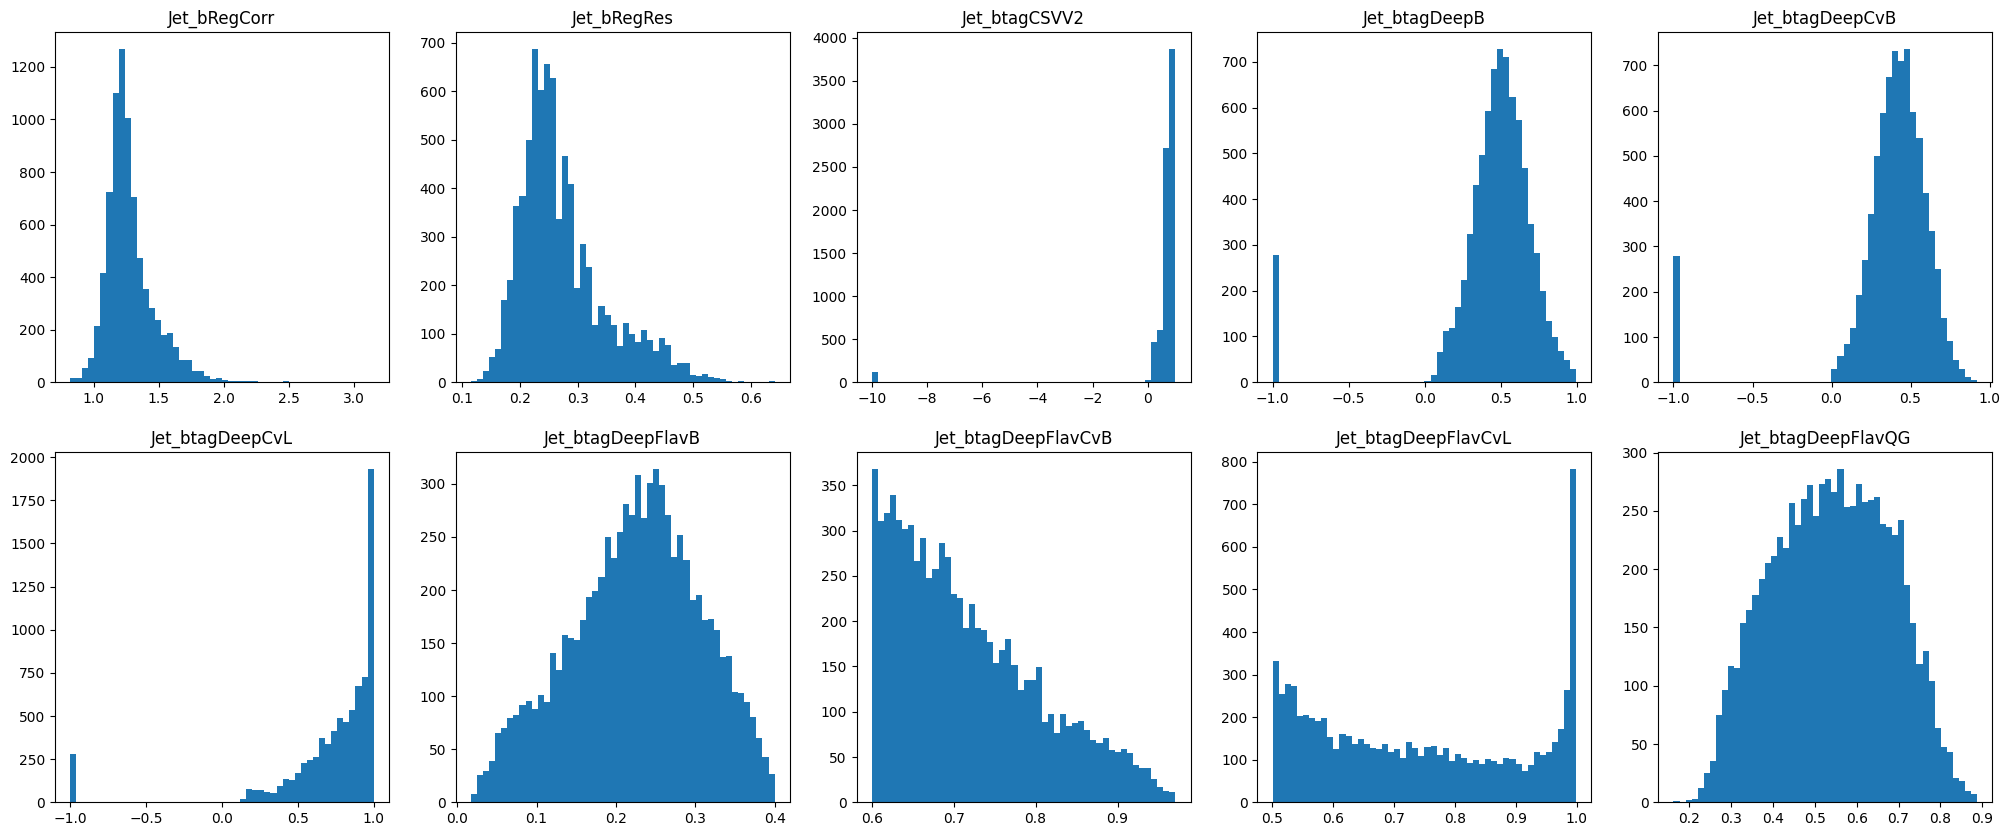

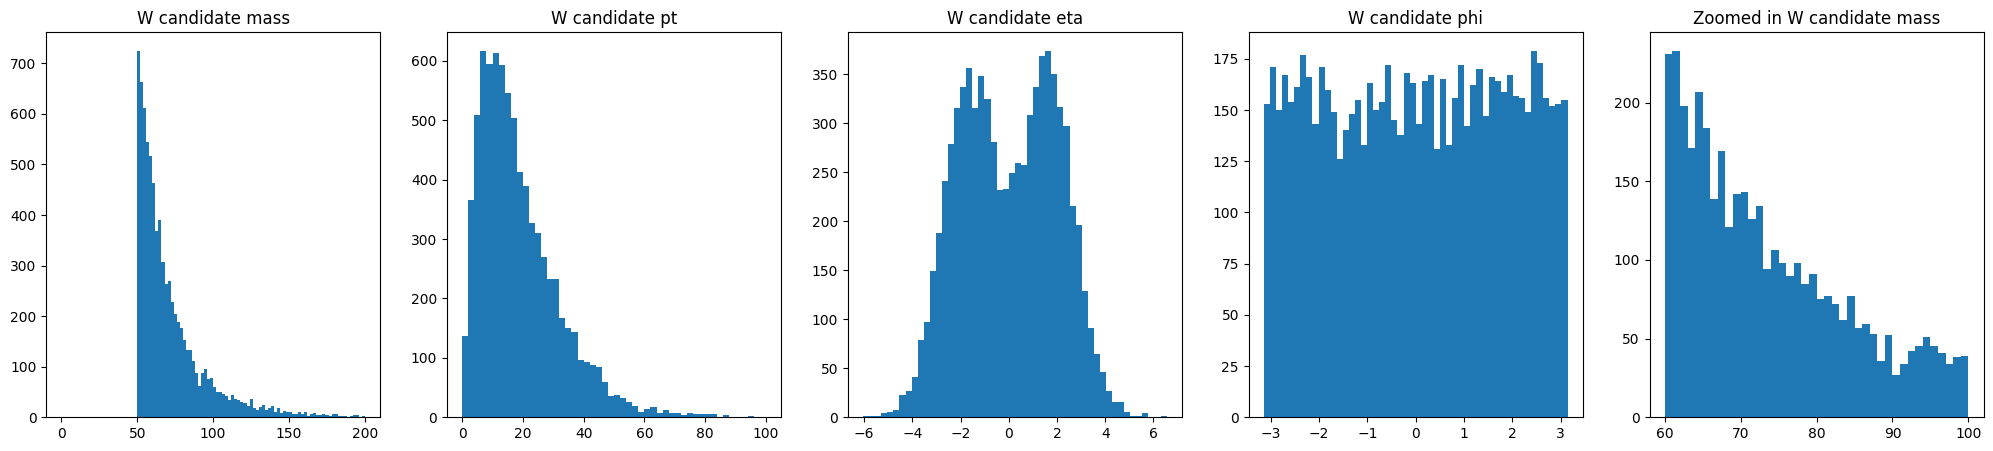

In [65]:
jet_df2, jet_desc2 = btag_req(df5, "DeepFlavCvB", 0.6, 2)
jet_desc2 += ", " + desc5
full_hist(jet_df2, jet_desc2)

jpsi mass within range 0 to 3.3, Jet_btagDeepFlavCvB in range: 0.6 to 2, jet mass in range: 1.8 to 3.5, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


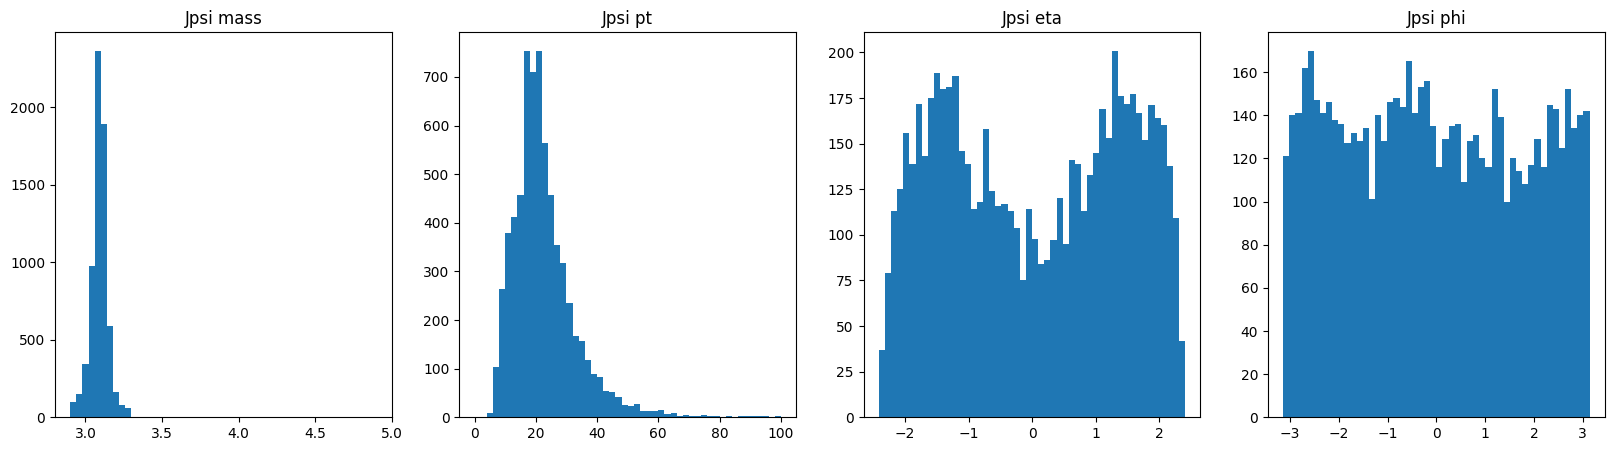

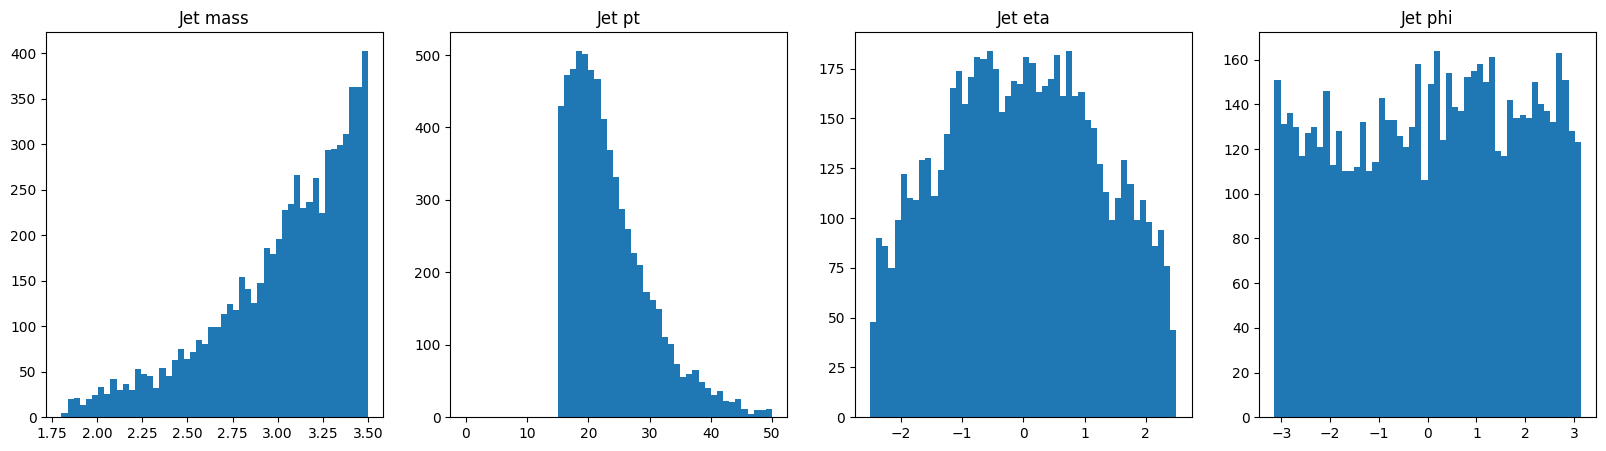

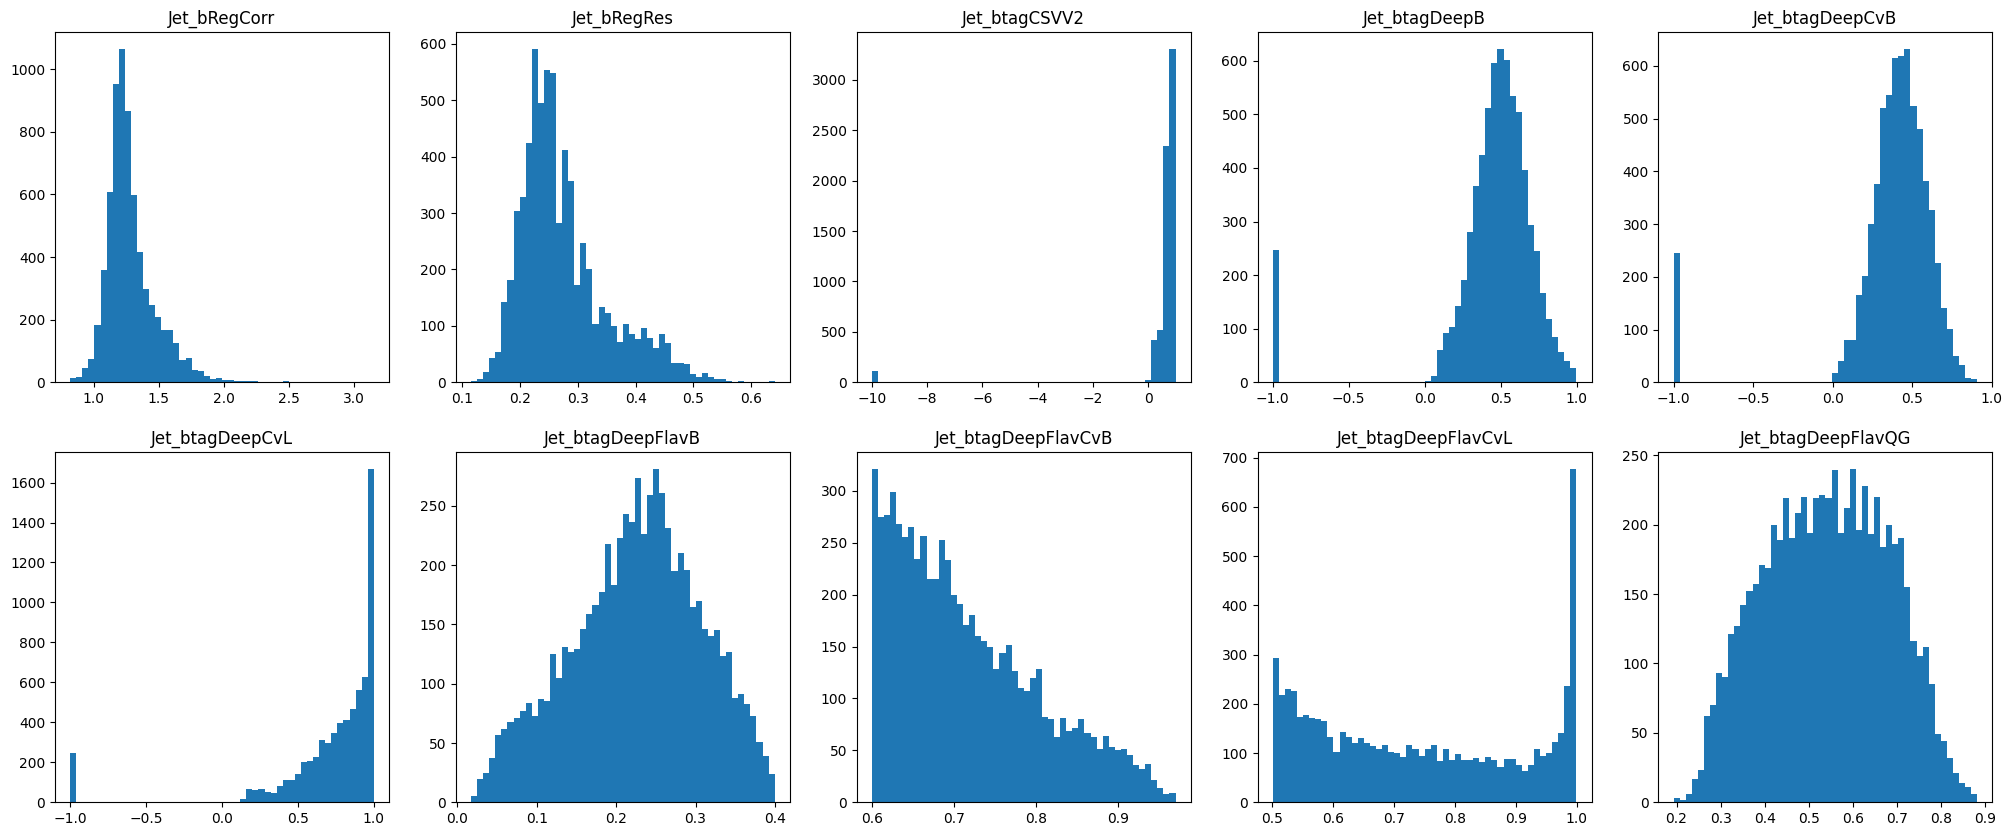

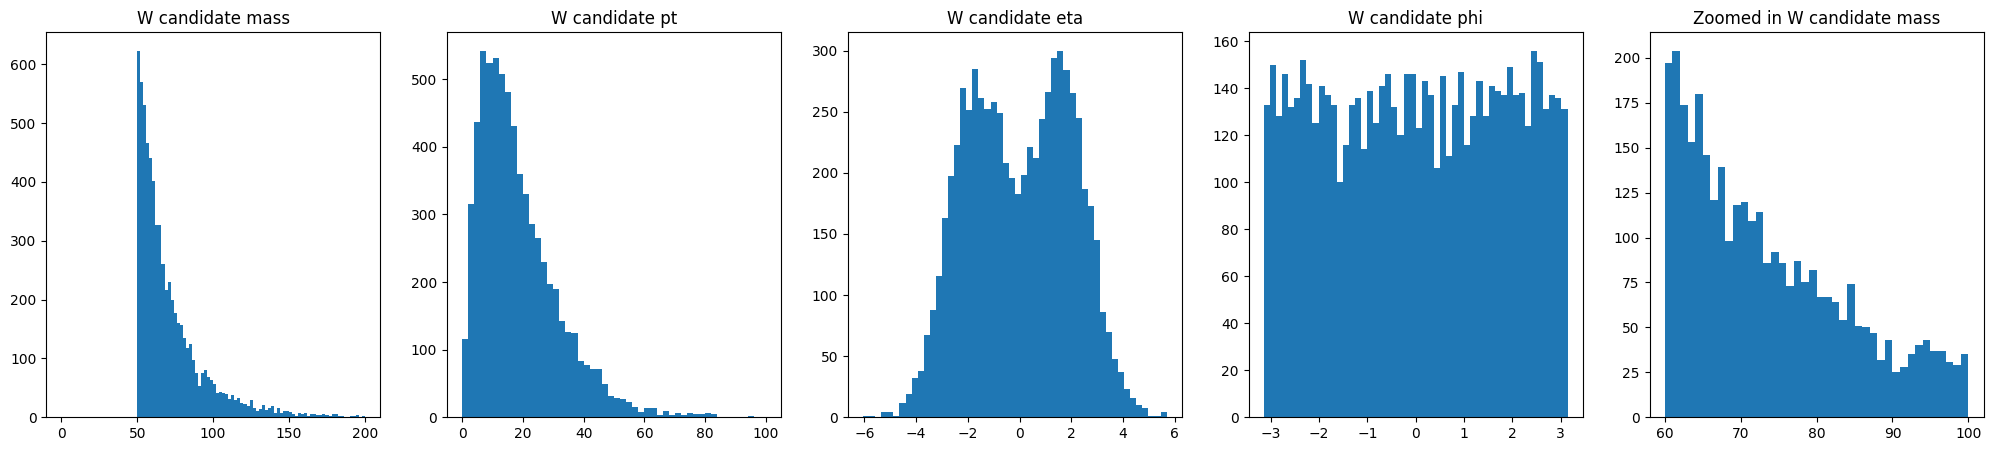

In [97]:
jpsi_df, jpsi_desc = jpsi_in(jet_df2, 0, 3.3)
jpsi_desc += ', '+jet_desc2
full_hist(jpsi_df,jpsi_desc)

jet mass in range: 1.8 to 3, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


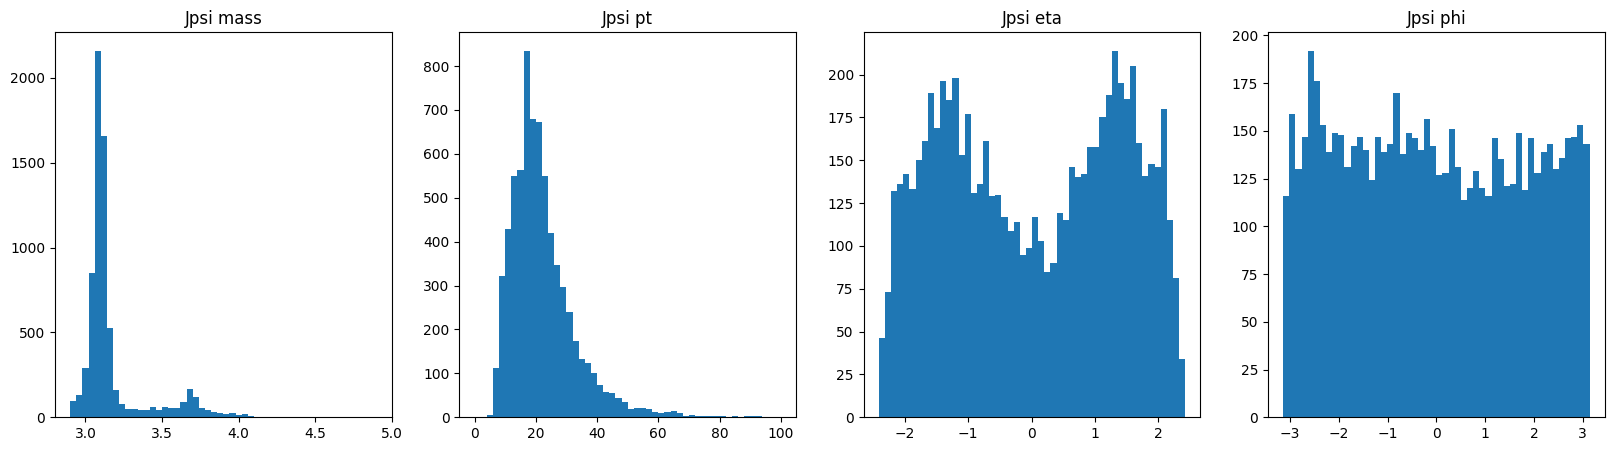

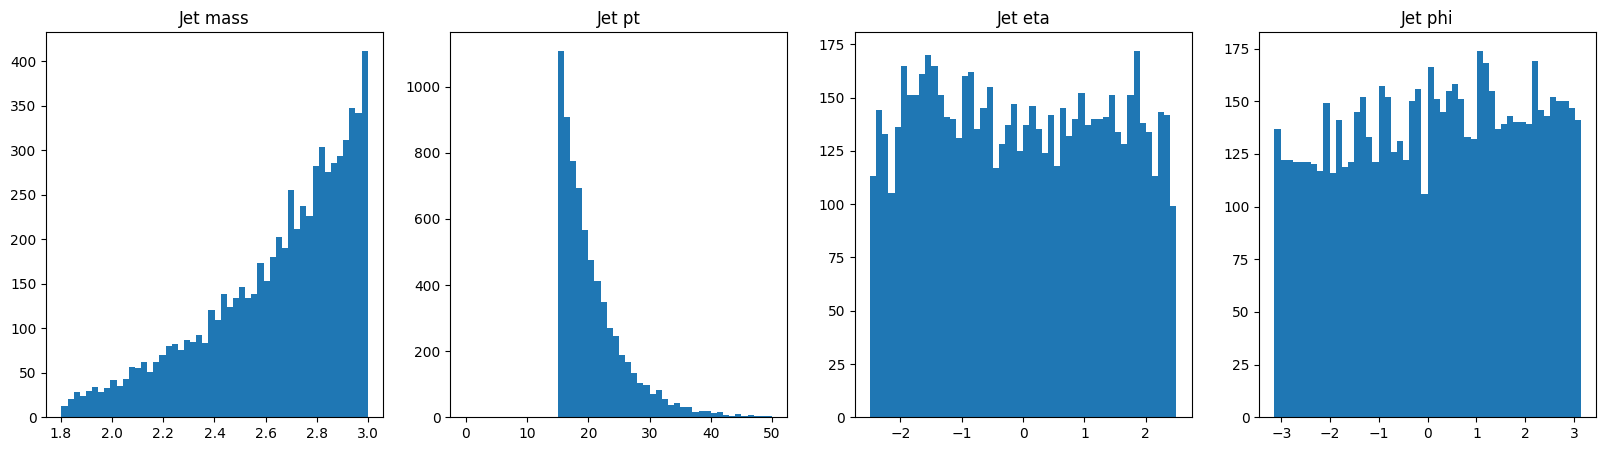

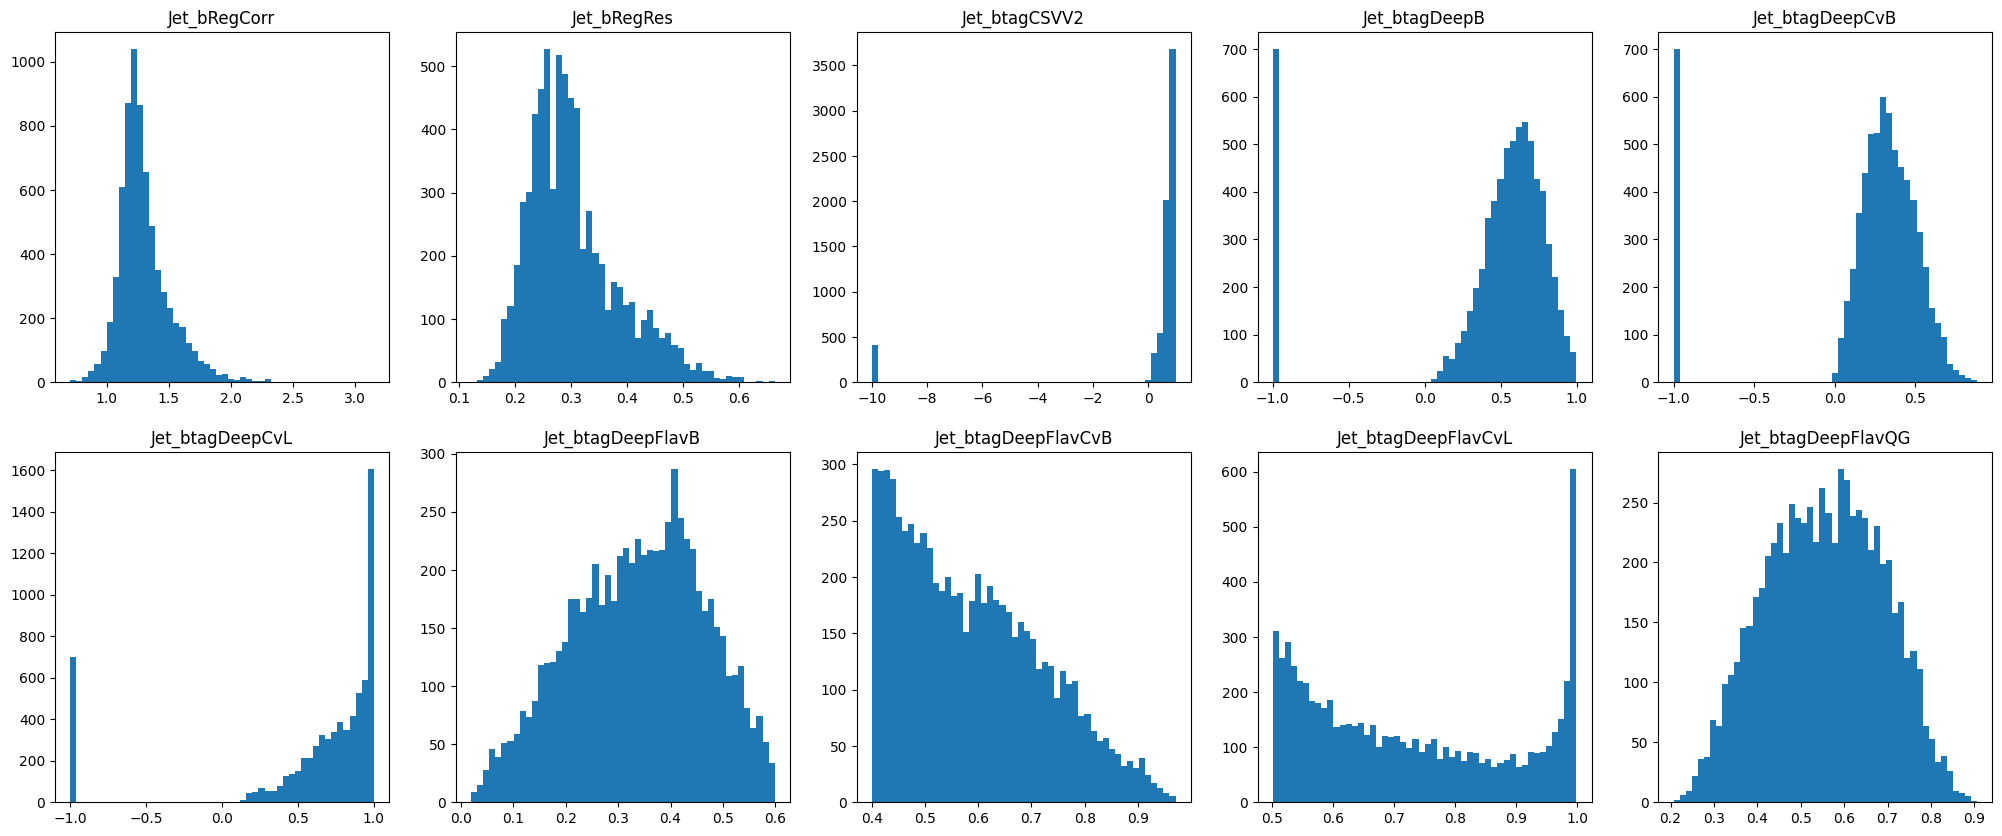

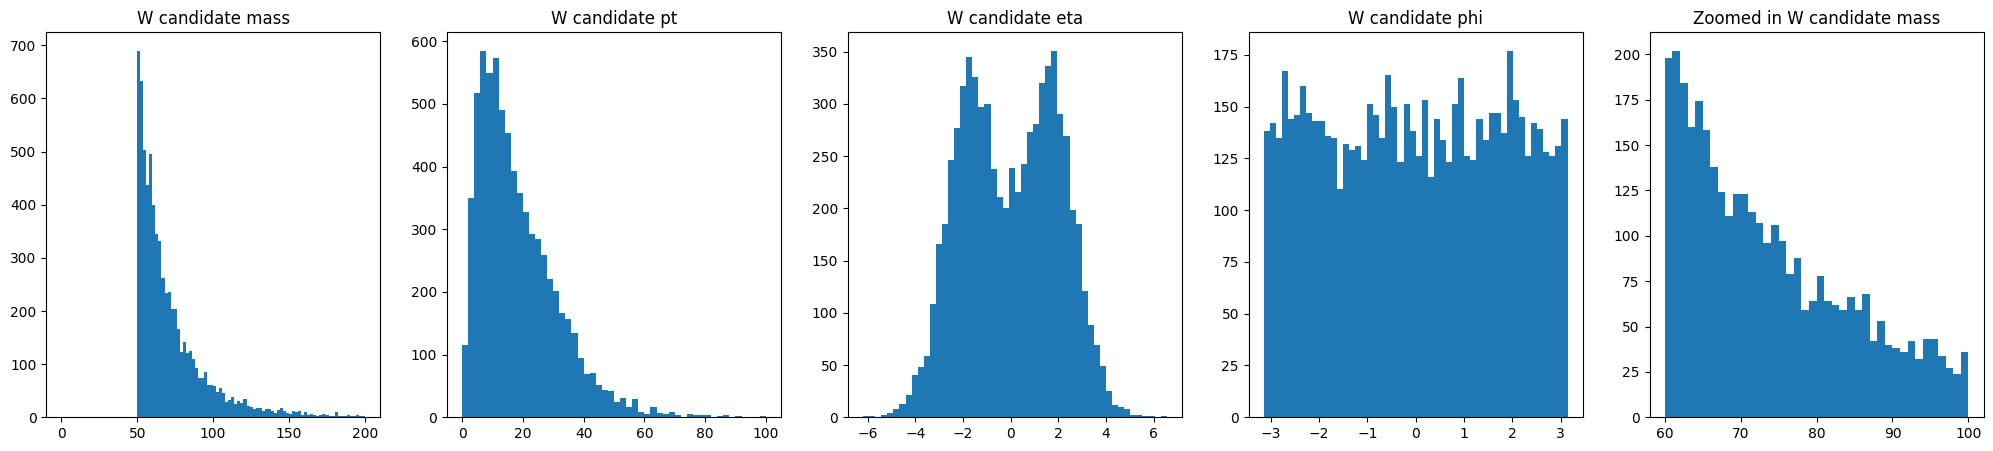

In [67]:
df6, desc6 = jet_req(df2, 1.8, 3)
desc6 += ", " + desc
full_hist(df6, desc6)

jet mass in range: 1.8 to 2.5, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


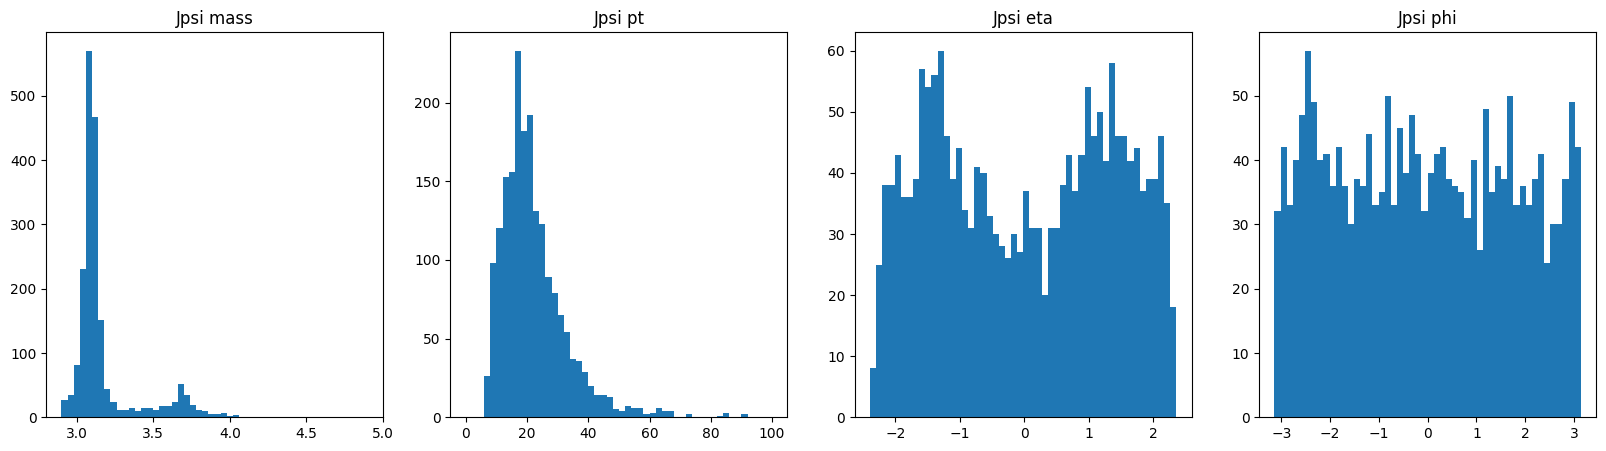

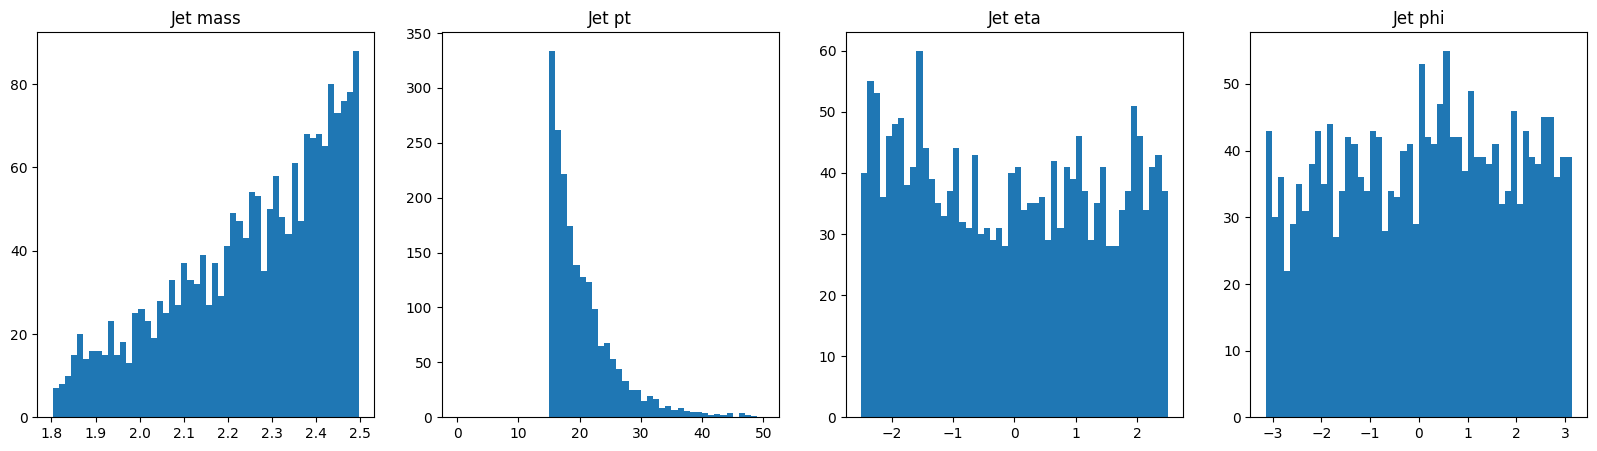

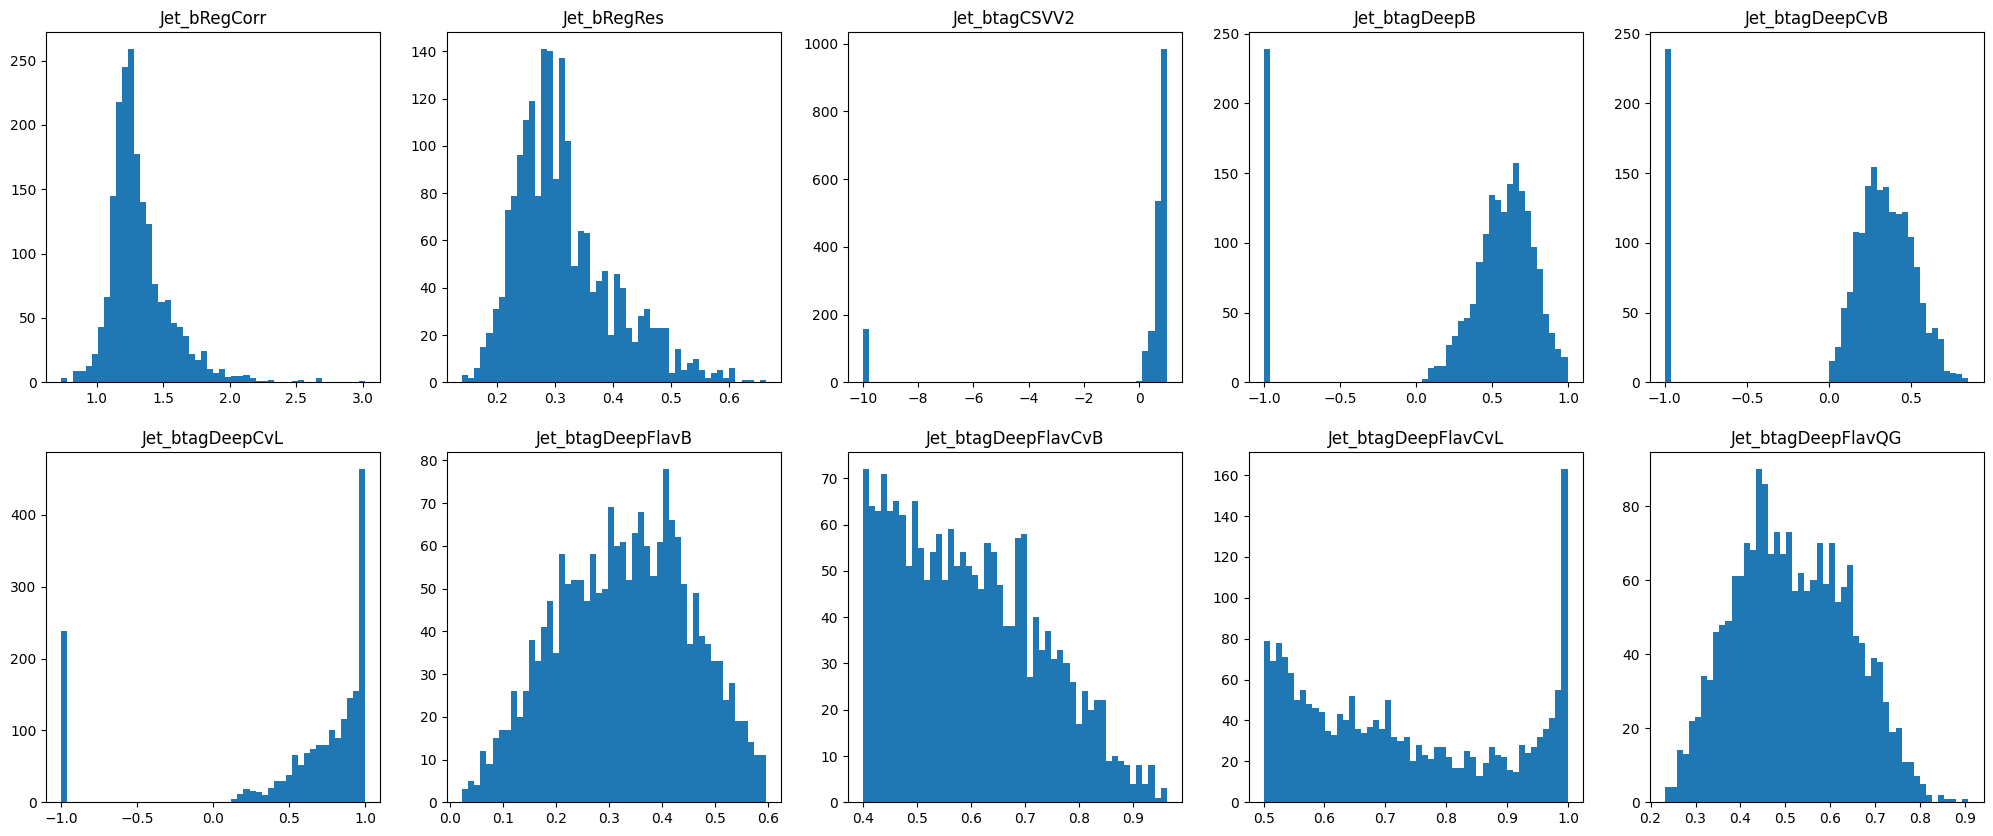

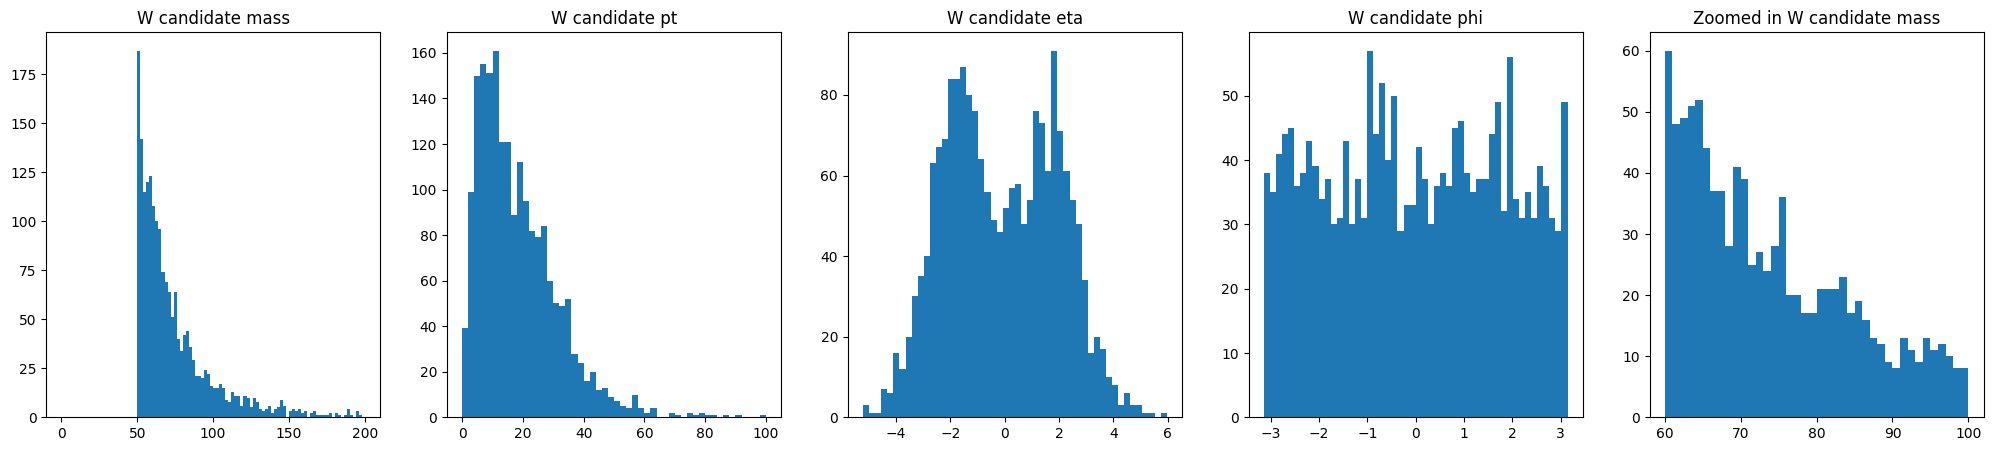

In [69]:
df7, desc7 = jet_req(df2, 1.8, 2.5)
desc7 += ", " + desc
full_hist(df7, desc7)

jpsi mass within range 0 to 3.3, jet mass in range: 1.8 to 2.5, Jet_btagDeepFlavCvB in range: 0.4 to 2, Jet_btagDeepFlavCvL in range: 0.5 to 2


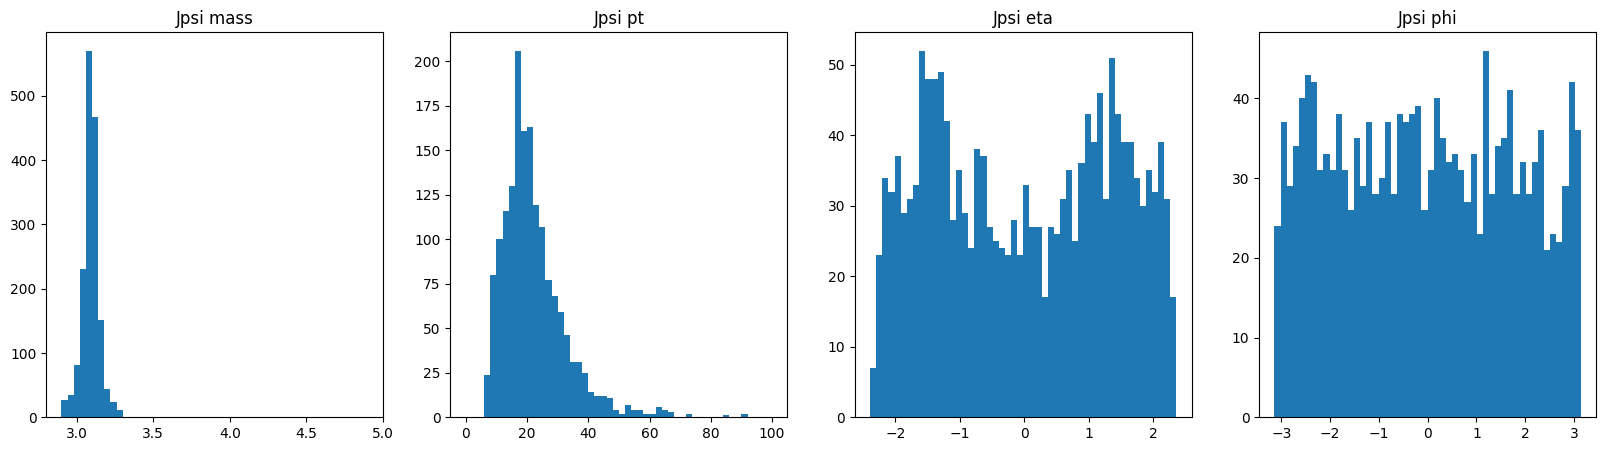

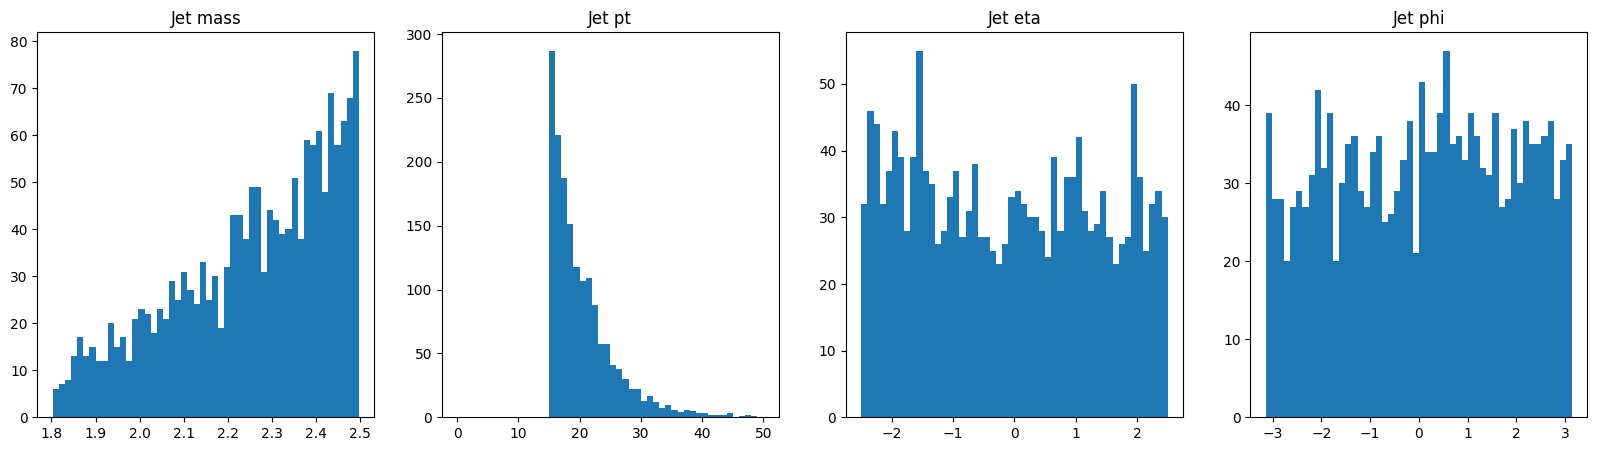

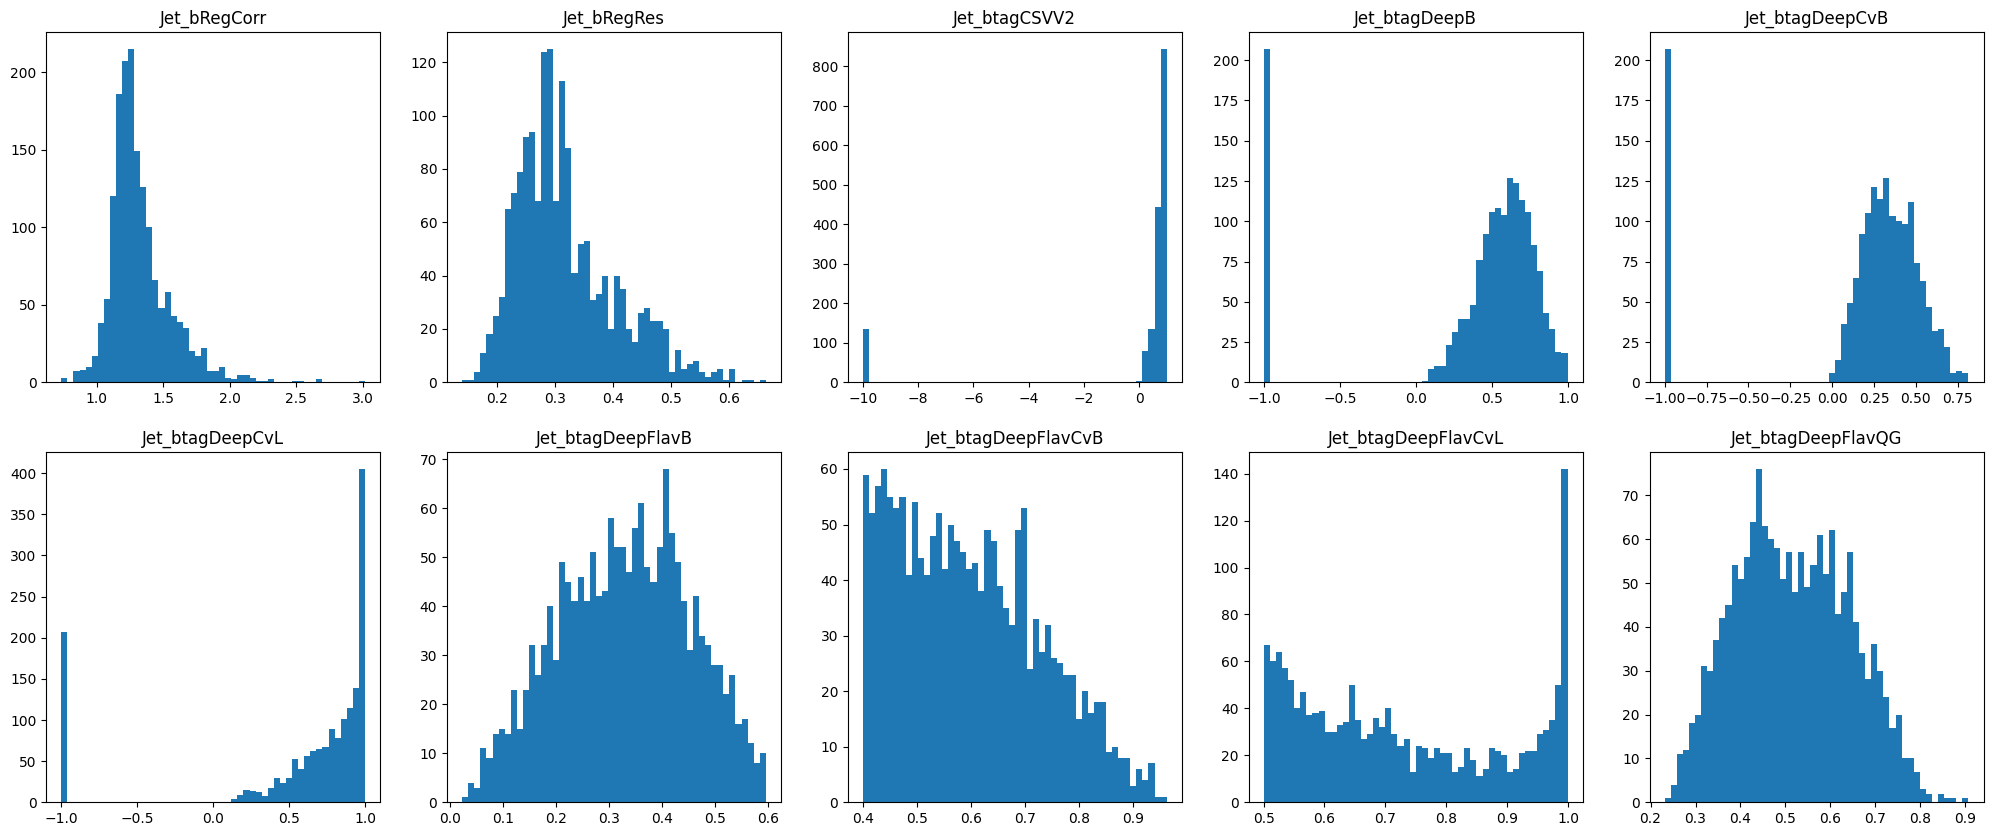

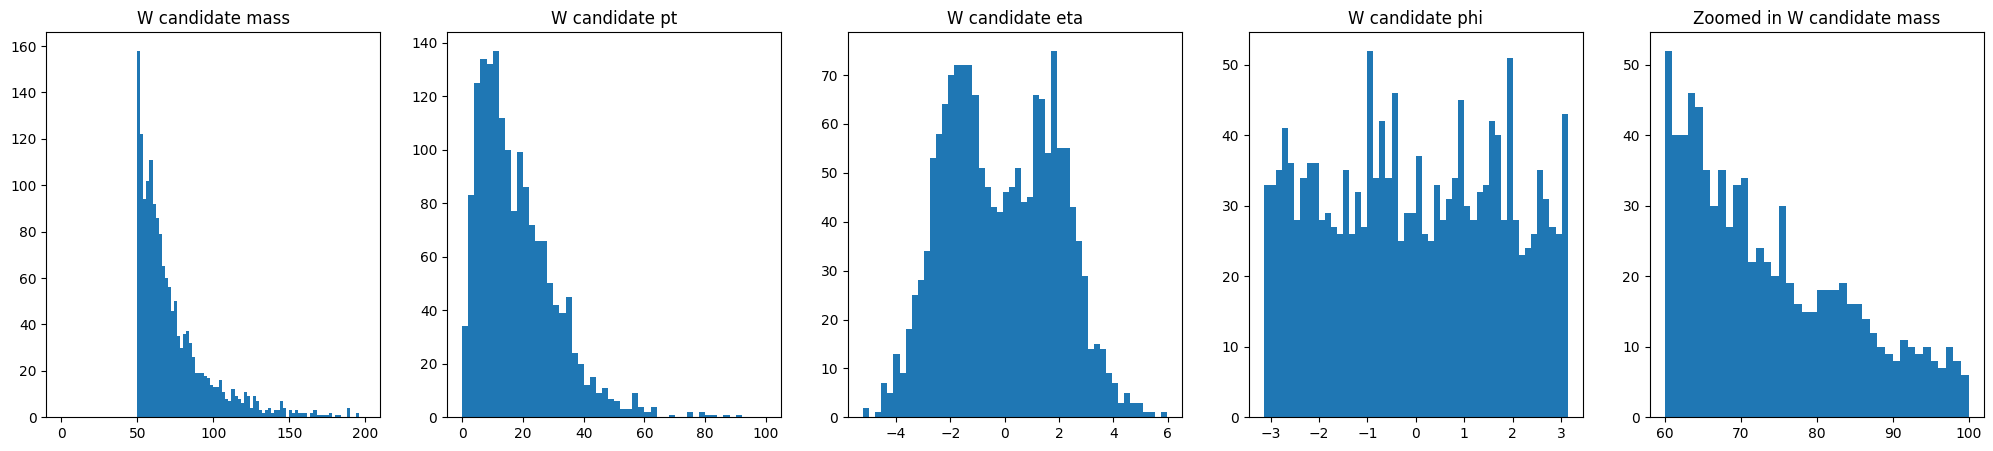

In [98]:
jpsi_df, jpsi_desc = jpsi_in(df7, 0, 3.3)
jpsi_desc += ', '+desc7
full_hist(jpsi_df,jpsi_desc)

[0.0064177297660536255, -1.3734154107681609, 78.41702639151384]
[52. 40. 40. 46. 44. 35. 30. 35. 27. 33. 34. 22. 24. 22. 20. 30. 19. 16.
 15. 15. 18. 18. 18. 19. 16. 16. 14. 12. 10.  9.  8. 11. 10.  9. 10.  8.
  7. 10.  8.  6.]
[32.8840711  21.49607679 22.09458036 28.6795818  27.25108111 18.8090783
 14.35357336 19.88456629 12.40205709 18.90604577 20.39653232  8.87351675
 11.33699904  9.78697921  8.22345725 18.64643317  8.05590696  5.45187862
  4.83434815  5.20331556  8.55878084  8.90074399  9.22920502 10.54416392
  7.84562069  8.13357534  6.40802785  4.66897825  2.91642651  2.15037265
  1.37081666  4.57775854  3.77119829  2.95113592  4.11757142  2.2705048
  1.40993605  4.53586517  2.64829216  0.74721702]


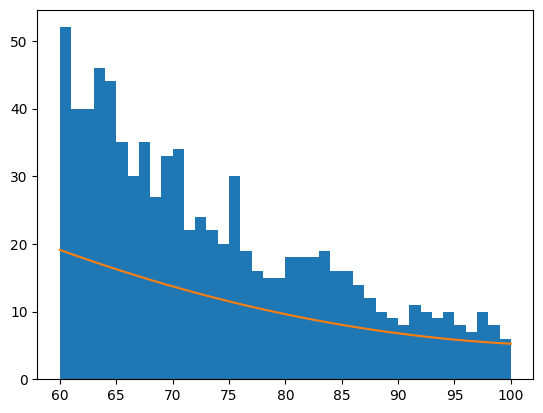

In [131]:
ratio = len(jpsi_df)/len(df)
p1 = [ 5.01959190e+01, -1.07420928e+04,  6.13334442e+05]
new_p = [p1[0]*ratio,p1[1]*ratio,p1[2]*ratio]
print(new_p)
vals, edges, fig = plt.hist(jpsi_df.wc_mass, bins = 40, range = (60,100))
x = np.linspace(60,100,40)
y = poly_eq(new_p,x)
plt.plot(x,y)
print(vals)
flat_vals = vals - y
print(flat_vals)

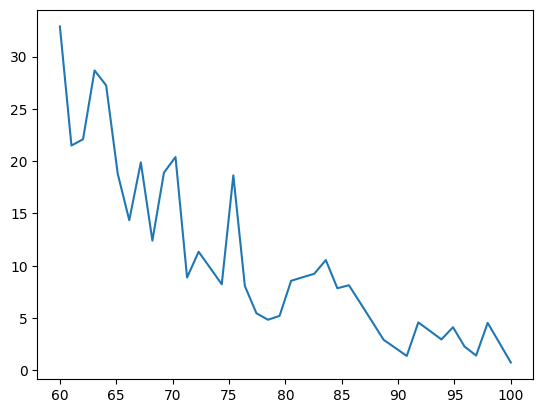

In [132]:
plt.plot(x,flat_vals)

[0.026590291490230906, -5.18380466660746, 260.84205526998227]
[52. 40. 40. 46. 44. 35. 30. 35. 27. 33. 34. 22. 24. 22. 20. 30. 19. 16.
 15. 15. 18. 18. 18. 19. 16. 16. 14. 12. 10.  9.  8. 11. 10.  9. 10.  8.
  7. 10.  8.  6.]
[ 6.46117536 -3.52272454 -1.5625672   6.34164738  6.18991921 -1.01775172
 -4.28136541  2.39907815 -3.97642105  3.59213699  6.10475228 -4.43857519
 -1.03784542 -1.6930584  -2.40421414  8.82868737 -0.99435389 -2.8733379
 -2.80826466 -1.79913418  2.15405354  3.0512985   3.89260071  5.67796016
  3.40737686  4.08085079  2.69838198  1.2599704  -0.23438393 -0.78468102
 -1.39092086  1.94689654  1.22877118  0.45470306  1.62469219 -0.26126144
 -1.20315782  1.79900304 -0.25477886 -2.36450351]


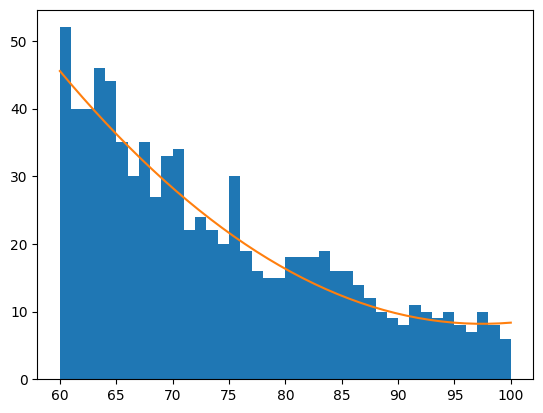

In [126]:
p2 = [ 1.00472041e+00, -1.95871277e+02,  9.85597833e+03]
ratio2 = len(jpsi_df)/len(df2)
new_p = [p2[0]*ratio2,p2[1]*ratio2,p2[2]*ratio2]
print(new_p)
vals, edges, fig = plt.hist(jpsi_df.wc_mass, bins = 40, range = (60,100))
x = np.linspace(60,100,40)
y = poly_eq(new_p,x)
plt.plot(x,y)
print(vals)
flat_vals2 = vals - y
print(flat_vals2)

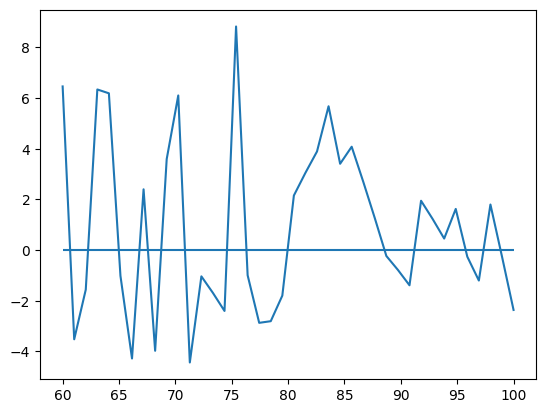

In [129]:
plt.plot(x,flat_vals2)
plt.hlines(y=0,xmin=60,xmax=100)